## Analisis de Variables de las Secuencias
#### Se calculan directamente desde la base de datos creada

In [2]:
# Conexión a la base de datos

from pathlib import Path 

def encontrar_raiz_proyecto():
    actual = Path.cwd().resolve()

    for carpeta in [actual, *actual.parents]:
        db = carpeta / "02_procesamiento" / "tesis.db"
        analisis = carpeta / "04_analisis"

        if db.is_file() and analisis.is_dir():
            return carpeta

    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. "
        "Iniciá Jupyter desde el repositorio o una subcarpeta."
    )

BASE = encontrar_raiz_proyecto()

DB = BASE / "02_procesamiento" / "tesis.db"


RESULTADOS = BASE / "04_analisis" / "Resultados" / "analisis_secuencias"
FIGURAS = BASE / "04_analisis" / "Figuras" / "analisis_secuencias"

RESULTADOS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

print(DB)

/home/matias-zabala/Descargas/Tesina/secuencias/tesis.db


In [3]:
import sqlite3

conexion = sqlite3.connect(DB)

In [4]:
#Librerias
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from Bio import SeqIO
from itertools import combinations

## 1. Longitud de las secuencias

Se analiza la longitud de las secuencias completas correspondientes a los
marcadores mitocondriales 12S, 16S y COI.

La longitud se expresa en pares de bases (pb).

In [5]:
consulta_longitud = """
SELECT
    e.nombre_cientifico AS especie,
    m.accession,
    s.gen,
    s.longitud
FROM Secuencia s
JOIN Muestra m
    ON s.id_muestra = m.id_muestra
JOIN Especie e
    ON m.id_especie = e.id_especie
ORDER BY s.gen, e.nombre_cientifico;
"""

df_longitud = pd.read_sql_query(consulta_longitud, conexion)

df_longitud

,especie,accession,gen,longitud
0,Acipenser baerii,AB1368,12S,961
1,Acipenser baerii,F20-045,12S,961
2,Acipenser baerii,F20-043,12S,961
3,Acipenser gueldenstaedtii,Dinoville,12S,961
4,Acipenser gueldenstaedtii,Complete genome,12S,961
...,...,...,...,...
250,Salvelinus namaycush,NEFC_F16-012,COI,1551
251,Salvelinus namaycush,NEFC_F16-461,COI,1551
252,Salvelinus namaycush,UAM:Fish:10464:374966,COI,1551
253,Xiphophorus maculatus,Complete genome,COI,1557


In [6]:
#Celda Control
#df_longitud.info()
#df_longitud["gen"].value_counts()
#df_longitud["longitud"].isna().sum()
df_longitud.groupby("gen")["longitud"].agg(["min", "max"])

,min,max
gen,,
12S,942,1013
16S,1641,1702
COI,1551,1596


In [7]:
resumen_longitud = (
    df_longitud
    .groupby("gen")["longitud"]
    .agg(
        n="count",
        media="mean",
        mediana="median",
        desvio="std",
        minimo="min",
        maximo="max"
    )
    .round(2)
)

resumen_longitud

,n,media,mediana,desvio,minimo,maximo
gen,,,,,,
12S,85,951.95,947.0,10.94,942,1013
16S,85,1680.80,1679.0,10.99,1641,1702
COI,85,1553.86,1551.0,8.63,1551,1596


In [8]:
# Guardar tabla de resultados

resumen_longitud.to_csv(
    RESULTADOS / "resumen_longitud_marcadores.csv",
    index=True
)

In [9]:
orden_genes = ["12S", "16S", "COI"]

colores = {
    "12S": "#4C78A8",
    "16S": "#F58518",
    "COI": "#54A24B"
}

### Distribución de la longitud de los marcadores

Se representa la distribución de la longitud de las secuencias completas de
12S, 16S y COI. El boxplot muestra la mediana y el rango intercuartílico,
mientras que los puntos representan las secuencias individuales.


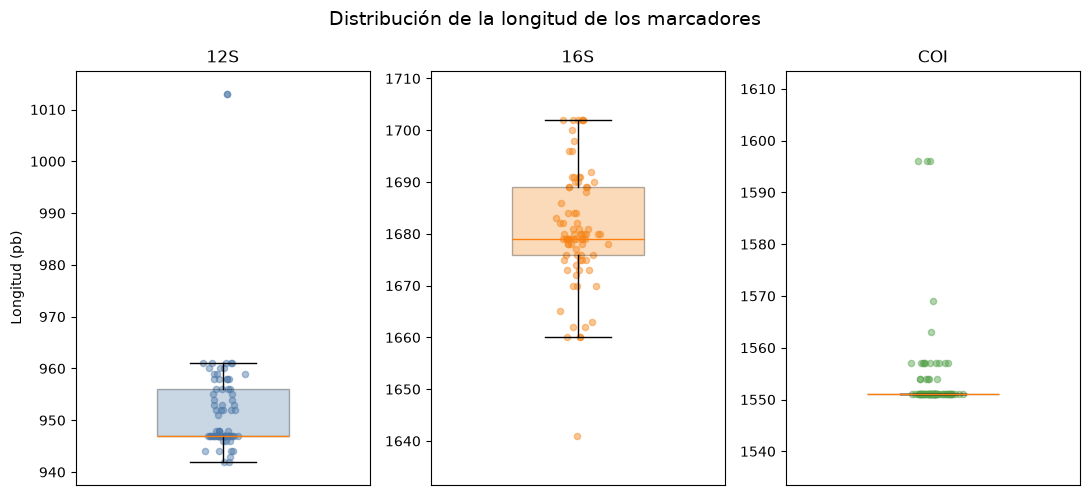

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 5))

rng = np.random.default_rng(42)


for ax, gen in zip(axes, orden_genes):

    datos = df_longitud.loc[
        df_longitud["gen"] == gen,
        "longitud"
    ]

    #Boxplot
    bp = ax.boxplot(
        datos,
        widths=0.45,
        showfliers=False,
        patch_artist = True
    )

    #Color de la caja
    for box in bp ["boxes"]:
        box.set_facecolor(colores[gen])
        box.set_alpha(0.30)


    jitter = rng.normal(1, 0.035, size=len(datos))

    ax.scatter(
        jitter,
        datos,
        alpha=0.45,
        s=20,
        color = colores[gen]
    )

    # Misma amplitud del eje Y: 80 pb
    centro = (datos.min() + datos.max()) / 2
    ax.set_ylim(centro - 40, centro + 40)

    ax.set_title(gen)
    ax.set_xticks([])

axes[0].set_ylabel("Longitud (pb)")

fig.suptitle(
    "Distribución de la longitud de los marcadores",
    fontsize=14
)

plt.tight_layout()

# Guardar PNG
plt.savefig(
    FIGURAS / "longitud_marcadores.png",
    dpi=300,
    bbox_inches="tight"
)

# Guardar PDF
plt.savefig(
    FIGURAS / "longitud_marcadores.pdf",
    bbox_inches="tight"
)

plt.show()

## 2. Contenido GC

El contenido GC corresponde a la proporción porcentual de guanina y citosina
respecto del total de nucleótidos válidos de cada secuencia completa.

Se calcula sobre las secuencias originales, sin considerar gaps ni caracteres
ambiguos.

Esta es una variable influyente en las propiedades fisicoquimicas del ADN.

In [11]:
consulta_gc = """
SELECT
    e.nombre_cientifico AS especie,
    m.accession,
    s.gen,
    s.archivo_fasta
FROM Secuencia s
JOIN Muestra m
    ON s.id_muestra = m.id_muestra
JOIN Especie e
    ON m.id_especie = e.id_especie
ORDER BY s.gen, e.nombre_cientifico;
"""

df_gc = pd.read_sql_query(consulta_gc, conexion)

df_gc.head()

,especie,accession,gen,archivo_fasta
0,Acipenser baerii,AB1368,12S,genes_extraidos/12S/INV_Acipenser_baerii_AB136...
1,Acipenser baerii,F20-045,12S,genes_extraidos/12S/INV_Acipenser_baerii_F20-0...
2,Acipenser baerii,F20-043,12S,genes_extraidos/12S/INV_Acipenser_baerii_F20-0...
3,Acipenser gueldenstaedtii,Dinoville,12S,genes_extraidos/12S/INV_Acipenser_gueldenstaed...
4,Acipenser gueldenstaedtii,Complete genome,12S,genes_extraidos/12S/INV_Acipenser_gueldenstaed...


In [12]:
def calcular_gc(ruta_fasta):

    registro = SeqIO.read(ruta_fasta, "fasta")

    secuencia = str(registro.seq).upper()

    a = secuencia.count("A")
    t = secuencia.count("T")
    g = secuencia.count("G")
    c = secuencia.count("C")

    total = a + t + g + c

    if total == 0:
        return np.nan

    gc = ((g + c) / total) * 100

    return gc

In [13]:
df_gc["ruta_fasta"] = df_gc["archivo_fasta"].apply(
    lambda x: BASE / "02_procesamiento" / x
)

df_gc["GC"] = df_gc["ruta_fasta"].apply(calcular_gc)

df_gc.head()

,especie,accession,gen,archivo_fasta,ruta_fasta,GC
0,Acipenser baerii,AB1368,12S,genes_extraidos/12S/INV_Acipenser_baerii_AB136...,/home/matias-zabala/Descargas/Tesina/secuencia...,48.595213
1,Acipenser baerii,F20-045,12S,genes_extraidos/12S/INV_Acipenser_baerii_F20-0...,/home/matias-zabala/Descargas/Tesina/secuencia...,48.595213
2,Acipenser baerii,F20-043,12S,genes_extraidos/12S/INV_Acipenser_baerii_F20-0...,/home/matias-zabala/Descargas/Tesina/secuencia...,48.595213
3,Acipenser gueldenstaedtii,Dinoville,12S,genes_extraidos/12S/INV_Acipenser_gueldenstaed...,/home/matias-zabala/Descargas/Tesina/secuencia...,48.699272
4,Acipenser gueldenstaedtii,Complete genome,12S,genes_extraidos/12S/INV_Acipenser_gueldenstaed...,/home/matias-zabala/Descargas/Tesina/secuencia...,48.699272


In [14]:
#Celda Control
df_gc["GC"].isna().sum()

df_gc.groupby("gen")["GC"].agg(["min", "max"])

,min,max
gen,,
12S,43.418259,50.686378
16S,40.526001,48.898154
COI,39.845261,48.053606


In [15]:
resumen_gc = (
    df_gc
    .groupby("gen")["GC"]
    .agg(
        n="count",
        media="mean",
        mediana="median",
        desvio="std",
        minimo="min",
        maximo="max"
    )
    .round(2)
)

resumen_gc


,n,media,mediana,desvio,minimo,maximo
gen,,,,,,
12S,85,48.87,49.37,1.63,43.42,50.69
16S,85,45.46,45.49,2.34,40.53,48.90
COI,85,44.97,45.58,1.83,39.85,48.05


In [16]:
resumen_gc.to_csv(
    RESULTADOS / "resumen_gc_marcadores.csv",
    index=True
)

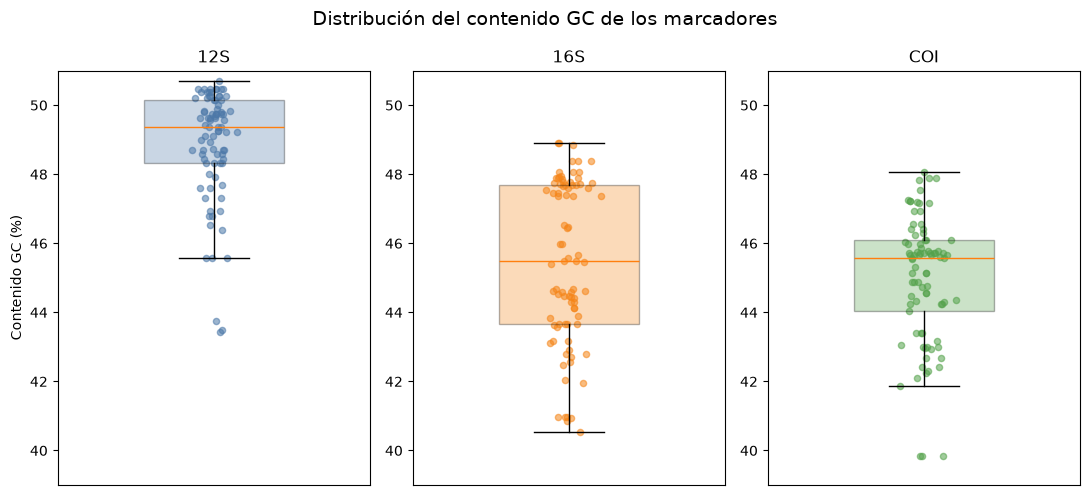

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11, 5))

rng = np.random.default_rng(42)

for ax, gen in zip(axes, orden_genes):

    datos = df_gc.loc[
        df_gc["gen"] == gen,
        "GC"
    ]

    # Boxplot
    bp = ax.boxplot(
        datos,
        widths=0.45,
        showfliers=False,
        patch_artist=True
    )

    for box in bp["boxes"]:
        box.set_facecolor(colores[gen])
        box.set_alpha(0.30)

    # Puntos individuales
    jitter = rng.normal(1, 0.035, size=len(datos))

    ax.scatter(
        jitter,
        datos,
        alpha=0.55,
        s=20,
        color=colores[gen]
    )

    ax.set_ylim(39, 51)

    ax.set_title(gen, fontsize=12)
    ax.set_xticks([])

axes[0].set_ylabel("Contenido GC (%)")

fig.suptitle(
    "Distribución del contenido GC de los marcadores",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURAS / "contenido_gc_marcadores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "contenido_gc_marcadores.pdf",
    bbox_inches="tight"
)



plt.show()

## 3. Conservación de las secuencias

La conservación se evaluó a partir de los alineamientos múltiples de los
marcadores 12S, 16S y COI.

Una posición se consideró completamente conservada cuando todas las secuencias
evaluadas presentaron el mismo nucleótido válido (A, T, G o C).

La conservación se calculó tanto a nivel intraespecífico como global para
cada marcador.

In [18]:
# La tabla Alineamiento ya está definida en tesis.db.
# Este notebook utiliza la base de datos existente.
cursor = conexion.cursor()


In [19]:
# Alineamientos de especies no nativas (85 secuencias).
CARPETA_ALINEAMIENTOS = (
    BASE / "03_alineamientos" / "no_nativas"
)

alineamientos = {
    "12S": CARPETA_ALINEAMIENTOS / "12S_alineado.fasta",
    "16S": CARPETA_ALINEAMIENTOS / "16S_alineado.fasta",
    "COI": CARPETA_ALINEAMIENTOS / "COI_alineado.fasta",
}

for gen, ruta in alineamientos.items():
    if not ruta.is_file():
        raise FileNotFoundError(ruta)

    print(f"{gen}: {ruta}")


In [20]:
# Verificar los alineamientos sin modificar SQLite.
for gen, ruta in alineamientos.items():

    registros = list(SeqIO.parse(ruta, "fasta"))

    if len(registros) != 85:
        raise ValueError(
            f"{gen}: se esperaban 85 secuencias, "
            f"pero se encontraron {len(registros)}"
        )

    longitudes = {len(reg.seq) for reg in registros}

    if len(longitudes) != 1:
        raise ValueError(
            f"{gen}: las secuencias no tienen igual longitud"
        )

    print(
        f"[OK] {gen}: {len(registros)} secuencias, "
        f"{longitudes.pop()} posiciones"
    )


In [21]:
# Recuperar únicamente los alineamientos de 85 secuencias.
df_alineamientos = pd.read_sql_query(
    """
    SELECT
        gen,
        archivo_alineamiento,
        n_secuencias,
        longitud_alineamiento
    FROM Alineamiento
    WHERE n_secuencias = 85
    ORDER BY gen
    """,
    conexion
)

if len(df_alineamientos) != 3:
    raise ValueError(
        "Se esperaban tres alineamientos de especies no nativas."
    )

df_alineamientos


,gen,archivo_alineamiento,n_secuencias,longitud_alineamiento
0,12S,Alineamiento/12S_alineado.fasta,85,1053
1,16S,Alineamiento/16S_alineado.fasta,85,1795
2,COI,Alineamiento/COI_alineado.fasta,85,1597


In [22]:
consulta_metadata = """
SELECT
    e.nombre_cientifico AS especie,
    m.accession,
    s.gen,
    s.archivo_fasta
FROM Secuencia s
JOIN Muestra m
    ON s.id_muestra = m.id_muestra
JOIN Especie e
    ON m.id_especie = e.id_especie
"""

df_metadata = pd.read_sql_query(
    consulta_metadata,
    conexion
)

In [23]:
metadata = {}

for _, fila in df_metadata.iterrows():

    ruta = BASE / "02_procesamiento" / fila["archivo_fasta"]

    registro = SeqIO.read(ruta, "fasta")

    metadata[(fila["gen"], registro.id)] = {
        "especie": fila["especie"],
        "accession": fila["accession"]
    }

In [24]:
registros_alineados = []

for _, fila in df_alineamientos.iterrows():

    gen = fila["gen"]
    ruta = BASE / "02_procesamiento" / fila["archivo_alineamiento"]

    for registro in SeqIO.parse(ruta, "fasta"):

        clave = (gen, registro.id)

        if clave not in metadata:
            print("No encontrado:", clave)
            continue

        registros_alineados.append({
            "gen": gen,
            "especie": metadata[clave]["especie"],
            "accession": metadata[clave]["accession"],
            "id_fasta": registro.id,
            "secuencia": str(registro.seq).upper()
        })

df_alineado = pd.DataFrame(registros_alineados)

In [25]:
def calcular_conservacion(secuencias):

    secuencias = list(secuencias)

    if len(secuencias) < 2:
        return {
            "sitios_evaluados": np.nan,
            "sitios_conservados": np.nan,
            "conservacion_pct": np.nan
        }

    longitud = len(secuencias[0])

    sitios_evaluados = 0
    sitios_conservados = 0

    nucleotidos_validos = {"A", "T", "G", "C"}

    for i in range(longitud):

        columna = [seq[i] for seq in secuencias]

        validos = [
            nt for nt in columna
            if nt in nucleotidos_validos
        ]

        # Si no hay nucleótidos válidos, la posición no se evalúa
        if len(validos) == 0:
            continue

        sitios_evaluados += 1

        # Conservación estricta:
        # todos deben ser válidos y además idénticos
        if (
            len(validos) == len(columna)
            and len(set(validos)) == 1
        ):
            sitios_conservados += 1

    conservacion_pct = (
        sitios_conservados /
        sitios_evaluados *
        100
    )

    return {
        "sitios_evaluados": sitios_evaluados,
        "sitios_conservados": sitios_conservados,
        "conservacion_pct": conservacion_pct
    }

In [26]:
resultados_intra = []

for (gen, especie), grupo in df_alineado.groupby(
    ["gen", "especie"]
):

    resultado = calcular_conservacion(
        grupo["secuencia"]
    )

    resultados_intra.append({
        "gen": gen,
        "especie": especie,
        "n_secuencias": len(grupo),
        "sitios_evaluados": resultado["sitios_evaluados"],
        "sitios_conservados": resultado["sitios_conservados"],
        "conservacion_pct": resultado["conservacion_pct"]
    })

conservacion_intra = pd.DataFrame(
    resultados_intra
)

conservacion_intra["conservacion_pct"] = (
    conservacion_intra["conservacion_pct"]
    .round(2)
)

conservacion_intra.head(20)

,gen,especie,n_secuencias,sitios_evaluados,sitios_conservados,conservacion_pct
0,12S,Acipenser baerii,3,961.0,961.0,100.00
1,12S,Acipenser gueldenstaedtii,2,961.0,961.0,100.00
2,12S,Ameiurus nebulosus,3,960.0,955.0,99.48
3,12S,Carassius auratus,3,954.0,952.0,99.79
4,12S,Clarias gariepinus,1,NaN,NaN,NaN
5,12S,Coregonus clupeaformis,3,947.0,944.0,99.68
6,12S,Ctenopharyngodon idella,2,958.0,956.0,99.79
7,12S,Cyprinus Carpio,3,956.0,955.0,99.90
8,12S,Danio Rerio,3,952.0,952.0,100.00
9,12S,Gambusia affinis,2,947.0,947.0,100.00


In [27]:
conservacion_intra.to_csv(
    RESULTADOS / "conservacion_intraespecifica.csv",
    index=False
)

In [ ]:
resultados_global = []

for gen, grupo in df_alineado.groupby("gen"):

    resultado = calcular_conservacion(
        grupo["secuencia"]
    )

    resultados_global.append({
        "gen": gen,
        "n_secuencias": len(grupo),
        "longitud_alineamiento": len(
            grupo.iloc[0]["secuencia"]
        ),
        "sitios_evaluados": resultado["sitios_evaluados"],
        "sitios_conservados": resultado["sitios_conservados"],
        "conservacion_pct": resultad47o["conservacion_pct"]
    })

conservacion_global = pd.DataFrame(
    resultados_global
)

conservacion_global["conservacion_pct"] = (
    conservacion_global["conservacion_pct"]
    .round(2)
)

conservacion_global

,gen,n_secuencias,longitud_alineamiento,sitios_evaluados,sitios_conservados,conservacion_pct
0,12S,85,1053,1053,510,48.43
1,16S,85,1795,1795,693,38.61
2,COI,85,1597,1597,853,53.41


In [29]:
conservacion_global.to_csv(
    RESULTADOS / "conservacion_global_marcadores.csv",
    index=False
)

In [30]:
matriz_conservacion = conservacion_intra.pivot(
    index="especie",
    columns="gen",
    values="conservacion_pct"
)

matriz_conservacion = matriz_conservacion[
    ["12S", "16S", "COI"]
]

matriz_conservacion.to_csv(
    RESULTADOS / "matriz_conservacion_especie_marcador.csv"
)

matriz_conservacion

gen,12S,16S,COI
especie,,,
Acipenser baerii,100.00,99.94,99.94
Acipenser gueldenstaedtii,100.00,100.00,100.00
Ameiurus nebulosus,99.48,97.48,98.00
Carassius auratus,99.79,99.94,100.00
Clarias gariepinus,NaN,NaN,NaN
Coregonus clupeaformis,99.68,99.94,99.94
Ctenopharyngodon idella,99.79,99.88,99.81
Cyprinus Carpio,99.90,99.88,99.68
Danio Rerio,100.00,100.00,100.00


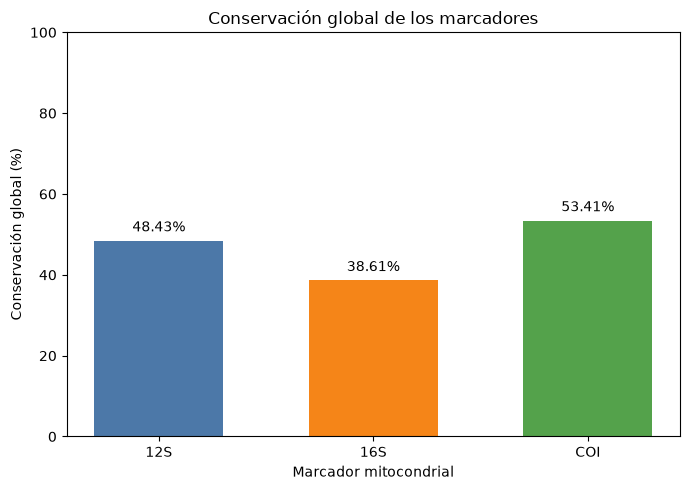

In [31]:
fig, ax = plt.subplots(figsize=(7, 5))

genes = ["12S", "16S", "COI"]

valores = [
    conservacion_global.loc[
        conservacion_global["gen"] == gen,
        "conservacion_pct"
    ].iloc[0]
    for gen in genes
]

barras = ax.bar(
    genes,
    valores,
    color=[colores[gen] for gen in genes],
    width=0.6
)

ax.set_ylabel("Conservación global (%)")
ax.set_xlabel("Marcador mitocondrial")
ax.set_title("Conservación global de los marcadores")

# Como estamos representando porcentajes
ax.set_ylim(0, 100)

# Mostrar el porcentaje sobre cada barra
for barra, valor in zip(barras, valores):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1.5,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    FIGURAS / "conservacion_global_marcadores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "conservacion_global_marcadores.pdf",
    bbox_inches="tight"
)

plt.show()

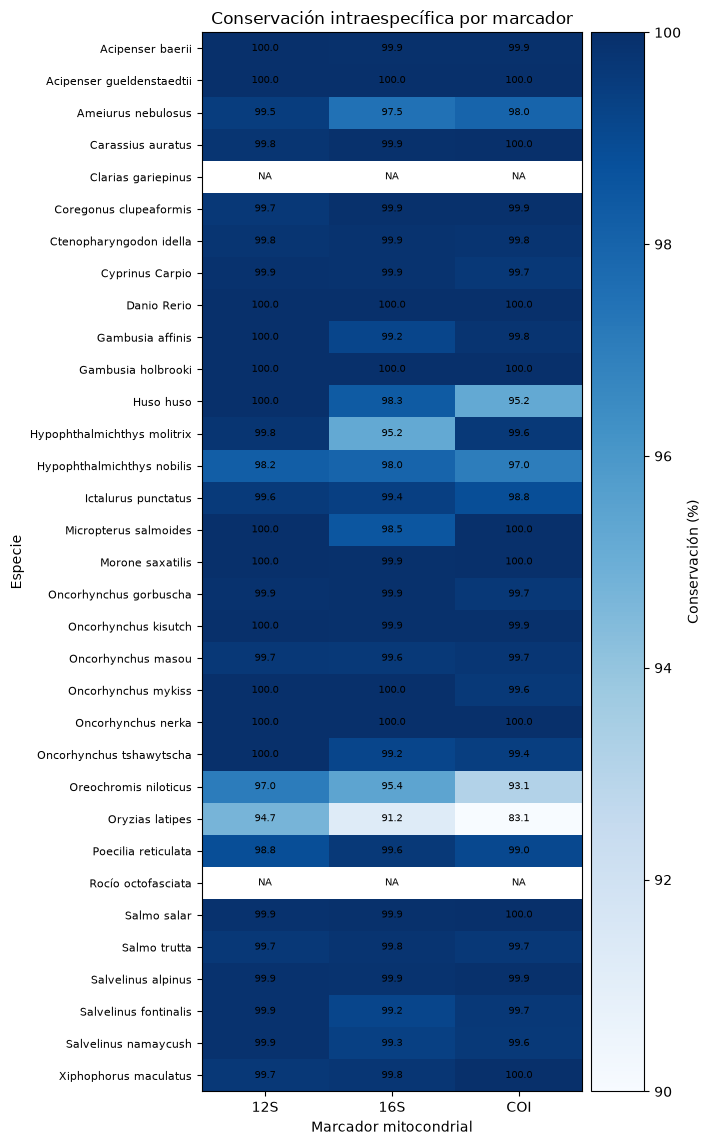

In [32]:
fig, ax = plt.subplots(
    figsize=(7, max(8, len(matriz_conservacion) * 0.35))
)

imagen = ax.imshow(
    matriz_conservacion.values,
    aspect="auto",
    cmap="Blues",
    vmin=90,
    vmax=100
)

# Eje X: marcadores
ax.set_xticks(range(len(matriz_conservacion.columns)))
ax.set_xticklabels(matriz_conservacion.columns)

# Eje Y: especies
ax.set_yticks(range(len(matriz_conservacion.index)))
ax.set_yticklabels(
    matriz_conservacion.index,
    fontsize=8
)

# Valores dentro de cada celda
for i in range(matriz_conservacion.shape[0]):
    for j in range(matriz_conservacion.shape[1]):

        valor = matriz_conservacion.iloc[i, j]

        if pd.notna(valor):
            texto = f"{valor:.1f}"
        else:
            texto = "NA"

        ax.text(
            j,
            i,
            texto,
            ha="center",
            va="center",
            fontsize=7,
            color="black"
        )

# Títulos y etiquetas
ax.set_xlabel("Marcador mitocondrial")
ax.set_ylabel("Especie")
ax.set_title("Conservación intraespecífica por marcador")

# Barra de color
cbar = fig.colorbar(
    imagen,
    ax=ax,
    pad=0.02
)

cbar.set_label("Conservación (%)")

plt.tight_layout()

# Guardar figuras
plt.savefig(
    FIGURAS / "conservacion_intraespecifica_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "conservacion_intraespecifica_heatmap.pdf",
    bbox_inches="tight"
)

plt.show()

## 4. Variabilidad intraespecífica e interespecífica

La variabilidad genética se evaluó mediante la distancia p entre pares de
secuencias alineadas. La distancia p corresponde a la proporción de posiciones
nucleotídicas diferentes respecto del total de posiciones válidas comparadas.

Las posiciones que presentaron gaps o caracteres ambiguos en cualquiera de
las dos secuencias fueron excluidas de la comparación mediante eliminación
por pares (pairwise deletion).

Se calcularon distancias intraespecíficas entre secuencias pertenecientes a
la misma especie y distancias interespecíficas entre secuencias pertenecientes
a especies diferentes.

In [33]:
def calcular_p_distance(seq1, seq2):

    validos = {"A", "T", "G", "C"}

    diferencias = 0
    sitios_comparados = 0

    for nt1, nt2 in zip(seq1, seq2):

        # Solo comparar posiciones con nucleótidos válidos
        # en ambas secuencias
        if nt1 in validos and nt2 in validos:

            sitios_comparados += 1

            if nt1 != nt2:
                diferencias += 1

    if sitios_comparados == 0:
        return np.nan

    return diferencias / sitios_comparados

In [34]:
resultados_intra_dist = []

for (gen, especie), grupo in df_alineado.groupby(
    ["gen", "especie"]
):

    secuencias = grupo.reset_index(drop=True)

    # Si hay menos de dos secuencias,
    # no se puede calcular variabilidad intraespecífica
    if len(secuencias) < 2:
        continue

    for i, j in combinations(range(len(secuencias)), 2):

        seq1 = secuencias.loc[i, "secuencia"]
        seq2 = secuencias.loc[j, "secuencia"]

        p = calcular_p_distance(seq1, seq2)

        resultados_intra_dist.append({
            "gen": gen,
            "especie": especie,
            "accession_1": secuencias.loc[i, "accession"],
            "accession_2": secuencias.loc[j, "accession"],
            "p_distance": p
        })

distancias_intra = pd.DataFrame(resultados_intra_dist)

distancias_intra.head()

,gen,especie,accession_1,accession_2,p_distance
0,12S,Acipenser baerii,AB1368,F20-043,0.000000
1,12S,Acipenser baerii,AB1368,F20-045,0.000000
2,12S,Acipenser baerii,F20-043,F20-045,0.000000
3,12S,Acipenser gueldenstaedtii,Complete genome,Dinoville,0.000000
4,12S,Ameiurus nebulosus,Complete genome,NEFCF16113,0.005208


In [35]:
distancias_intra.to_csv(
    RESULTADOS / "distancias_intraespecificas.csv",
    index=False
)

In [36]:
resultados_resumen_intra = []

for (gen, especie), grupo in df_alineado.groupby(
    ["gen", "especie"]
):

    n_secuencias = len(grupo)

    # Buscar las comparaciones de esa especie
    subset = distancias_intra[
        (distancias_intra["gen"] == gen) &
        (distancias_intra["especie"] == especie)
    ]

    n_comparaciones = len(subset)

    if n_comparaciones == 0:

        resultados_resumen_intra.append({
            "gen": gen,
            "especie": especie,
            "n_secuencias": n_secuencias,
            "n_comparaciones": 0,
            "media": np.nan,
            "mediana": np.nan,
            "minimo": np.nan,
            "maximo": np.nan
        })

    else:

        resultados_resumen_intra.append({
            "gen": gen,
            "especie": especie,
            "n_secuencias": n_secuencias,
            "n_comparaciones": n_comparaciones,
            "media": subset["p_distance"].mean(),
            "mediana": subset["p_distance"].median(),
            "minimo": subset["p_distance"].min(),
            "maximo": subset["p_distance"].max()
        })

resumen_intra = pd.DataFrame(
    resultados_resumen_intra
)

resumen_intra[
    ["media", "mediana", "minimo", "maximo"]
] = resumen_intra[
    ["media", "mediana", "minimo", "maximo"]
].round(5)

resumen_intra

,gen,especie,n_secuencias,n_comparaciones,media,mediana,minimo,maximo
0,12S,Acipenser baerii,3,3,0.00000,0.00000,0.00000,0.00000
1,12S,Acipenser gueldenstaedtii,2,1,0.00000,0.00000,0.00000,0.00000
2,12S,Ameiurus nebulosus,3,3,0.00347,0.00521,0.00000,0.00521
3,12S,Carassius auratus,3,3,0.00000,0.00000,0.00000,0.00000
4,12S,Clarias gariepinus,1,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
94,COI,Salmo trutta,3,3,0.00215,0.00258,0.00064,0.00322
95,COI,Salvelinus alpinus,3,3,0.00043,0.00064,0.00000,0.00064
96,COI,Salvelinus fontinalis,3,3,0.00215,0.00258,0.00064,0.00322
97,COI,Salvelinus namaycush,3,3,0.00258,0.00322,0.00129,0.00322


In [37]:
resultados_inter = []

for gen, grupo in df_alineado.groupby("gen"):

    grupo = grupo.reset_index(drop=True)

    for i, j in combinations(range(len(grupo)), 2):

        especie_1 = grupo.loc[i, "especie"]
        especie_2 = grupo.loc[j, "especie"]

        # Solo nos interesan pares de especies diferentes
        if especie_1 == especie_2:
            continue

        seq1 = grupo.loc[i, "secuencia"]
        seq2 = grupo.loc[j, "secuencia"]

        p = calcular_p_distance(seq1, seq2)

        resultados_inter.append({
            "gen": gen,
            "especie_1": especie_1,
            "especie_2": especie_2,
            "accession_1": grupo.loc[i, "accession"],
            "accession_2": grupo.loc[j, "accession"],
            "p_distance": p
        })

distancias_inter = pd.DataFrame(resultados_inter)

distancias_inter.head()

,gen,especie_1,especie_2,accession_1,accession_2,p_distance
0,12S,Acipenser baerii,Acipenser gueldenstaedtii,AB1368,Complete genome,0.001041
1,12S,Acipenser baerii,Acipenser gueldenstaedtii,AB1368,Dinoville,0.001041
2,12S,Acipenser baerii,Huso huso,AB1368,Complete Genome MK,0.013528
3,12S,Acipenser baerii,Huso huso,AB1368,Complete Genome MK,0.013528
4,12S,Acipenser baerii,Coregonus clupeaformis,AB1368,Complete Genome,0.169312


In [38]:
distancias_inter.to_csv(
    RESULTADOS / "distancias_interespecificas.csv",
    index=False
)

In [39]:
resumen_inter = (
    distancias_inter
    .groupby(
        ["gen", "especie_1", "especie_2"]
    )["p_distance"]
    .agg(
        n_comparaciones="count",
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

resumen_inter[
    ["media", "mediana", "minimo", "maximo"]
] = resumen_inter[
    ["media", "mediana", "minimo", "maximo"]
].round(5)

resumen_inter.head(20)


,gen,especie_1,especie_2,n_comparaciones,media,mediana,minimo,maximo
0,12S,Acipenser baerii,Acipenser gueldenstaedtii,6,0.00104,0.00104,0.00104,0.00104
1,12S,Acipenser baerii,Ameiurus nebulosus,9,0.17620,0.17479,0.17479,0.17903
2,12S,Acipenser baerii,Carassius auratus,9,0.18419,0.18413,0.18413,0.18432
3,12S,Acipenser baerii,Clarias gariepinus,3,0.16737,0.16737,0.16737,0.16737
4,12S,Acipenser baerii,Coregonus clupeaformis,9,0.16720,0.16614,0.16614,0.16931
5,12S,Acipenser baerii,Ctenopharyngodon idella,6,0.17778,0.17778,0.17672,0.17884
6,12S,Acipenser baerii,Cyprinus Carpio,9,0.18095,0.18095,0.18095,0.18095
7,12S,Acipenser baerii,Danio Rerio,9,0.22751,0.22751,0.22751,0.22751
8,12S,Acipenser baerii,Gambusia affinis,6,0.20148,0.20148,0.20148,0.20148
9,12S,Acipenser baerii,Gambusia holbrooki,6,0.20361,0.20361,0.20361,0.20361


In [40]:
resumen_inter.to_csv(
    RESULTADOS / "resumen_variabilidad_interespecifica.csv",
    index=False
)

In [41]:
resumen_inter_marcador = (
    distancias_inter
    .groupby("gen")["p_distance"]
    .agg(
        n_comparaciones="count",
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

resumen_inter_marcador[
    ["media", "mediana", "minimo", "maximo"]
] = resumen_inter_marcador[
    ["media", "mediana", "minimo", "maximo"]
].round(5)

resumen_inter_marcador

,gen,n_comparaciones,media,mediana,minimo,maximo
0,12S,3497,0.16261,0.18201,0.00104,0.26383
1,16S,3497,0.19489,0.22577,0.00529,0.28987
2,COI,3497,0.18775,0.20374,0.00901,0.23469


In [42]:
resumen_inter_marcador.to_csv(
    RESULTADOS / "resumen_inter_por_marcador.csv",
    index=False
)

In [43]:
matriz_intra = resumen_intra.pivot(
    index="especie",
    columns="gen",
    values="media"
)

matriz_intra = matriz_intra[
    ["12S", "16S", "COI"]
]

matriz_intra.to_csv(
    RESULTADOS / "matriz_variabilidad_intraespecifica.csv"
)

matriz_intra

gen,12S,16S,COI
especie,,,
Acipenser baerii,0.00000,0.00039,0.00000
Acipenser gueldenstaedtii,0.00000,0.00000,0.00000
Ameiurus nebulosus,0.00347,0.00691,0.01332
Carassius auratus,0.00000,0.00040,0.00000
Clarias gariepinus,NaN,NaN,NaN
Coregonus clupeaformis,0.00211,0.00040,0.00043
Ctenopharyngodon idella,0.00209,0.00059,0.00193
Cyprinus Carpio,0.00000,0.00079,0.00215
Danio Rerio,0.00000,0.00000,0.00000


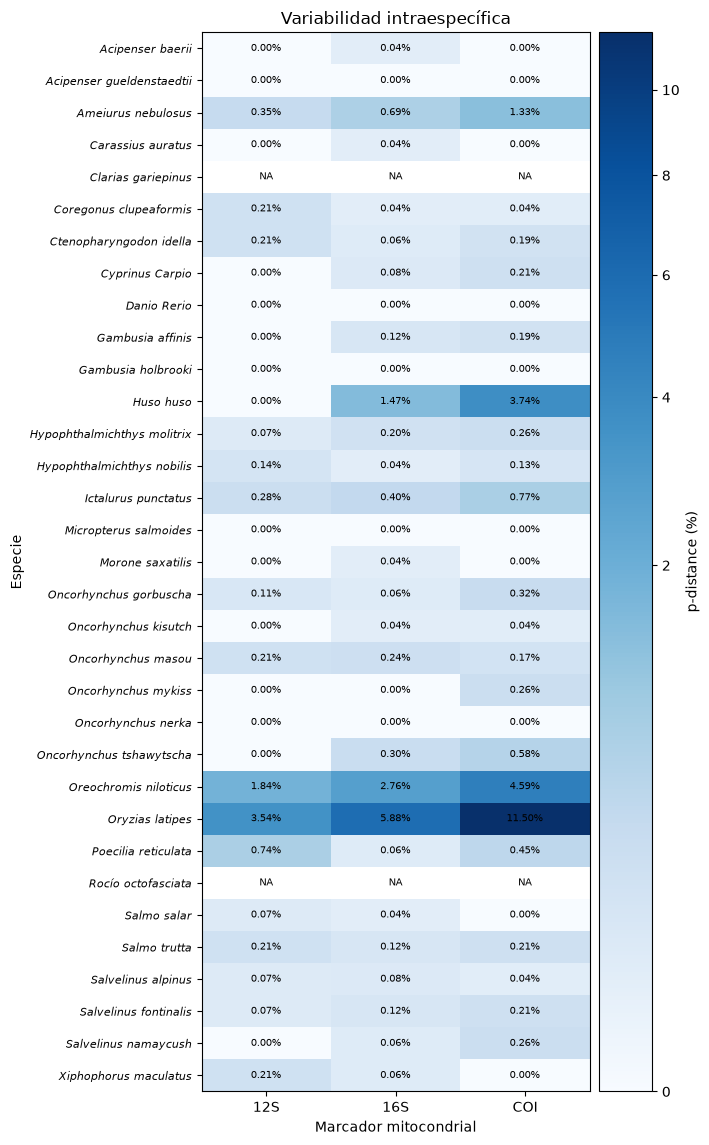

In [44]:
from matplotlib.colors import PowerNorm

# Convertir p-distance a porcentaje
matriz_intra_pct = matriz_intra * 100

fig, ax = plt.subplots(
    figsize=(7, max(8, len(matriz_intra_pct) * 0.35))
)

max_intra = np.nanmax(matriz_intra_pct.values)

imagen = ax.imshow(
    matriz_intra_pct.values,
    aspect="auto",
    cmap="Blues",
    norm=PowerNorm(
        gamma=0.4,
        vmin=0,
        vmax=max_intra
    )
)

# Eje X
ax.set_xticks(range(len(matriz_intra_pct.columns)))
ax.set_xticklabels(matriz_intra_pct.columns)

# Eje Y
ax.set_yticks(range(len(matriz_intra_pct.index)))
ax.set_yticklabels(
    matriz_intra_pct.index,
    fontsize=8,
    fontstyle="italic"
)

# Valores dentro de cada celda
for i in range(matriz_intra_pct.shape[0]):
    for j in range(matriz_intra_pct.shape[1]):

        valor = matriz_intra_pct.iloc[i, j]

        if pd.notna(valor):
            texto = f"{valor:.2f}%"
        else:
            texto = "NA"

        ax.text(
            j,
            i,
            texto,
            ha="center",
            va="center",
            fontsize=7
        )

ax.set_xlabel("Marcador mitocondrial")
ax.set_ylabel("Especie")
ax.set_title("Variabilidad intraespecífica")

# Barra de color
cbar = fig.colorbar(
    imagen,
    ax=ax,
    pad=0.02
)

cbar.set_label("p-distance (%)")

plt.tight_layout()

plt.savefig(
    FIGURAS / "variabilidad_intraespecifica_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "variabilidad_intraespecifica_heatmap.pdf",
    bbox_inches="tight"
)

plt.show()

In [45]:
distancias_inter_matriz = distancias_inter.copy()

distancias_inter_matriz["especie_a"] = distancias_inter_matriz.apply(
    lambda x: min(x["especie_1"], x["especie_2"]),
    axis=1
)

distancias_inter_matriz["especie_b"] = distancias_inter_matriz.apply(
    lambda x: max(x["especie_1"], x["especie_2"]),
    axis=1
)

pares_inter = (
    distancias_inter_matriz
    .groupby(
        ["gen", "especie_a", "especie_b"]
    )["p_distance"]
    .mean()
    .reset_index(name="p_distance_media")
)

pares_inter.head()

,gen,especie_a,especie_b,p_distance_media
0,12S,Acipenser baerii,Acipenser gueldenstaedtii,0.001041
1,12S,Acipenser baerii,Ameiurus nebulosus,0.176201
2,12S,Acipenser baerii,Carassius auratus,0.184192
3,12S,Acipenser baerii,Clarias gariepinus,0.167373
4,12S,Acipenser baerii,Coregonus clupeaformis,0.167196


In [46]:
def crear_matriz_inter(gen):

    datos = pares_inter[
        pares_inter["gen"] == gen
    ]

    especies = sorted(
        set(datos["especie_a"]) |
        set(datos["especie_b"])
    )

    matriz = pd.DataFrame(
        np.nan,
        index=especies,
        columns=especies,
        dtype=float
    )

    # Distancia de cada especie consigo misma = 0
    for especie in especies:
        matriz.loc[especie, especie] = 0.0

    # Completar ambas mitades de la matriz
    for _, fila in datos.iterrows():

        esp1 = fila["especie_a"]
        esp2 = fila["especie_b"]
        distancia = fila["p_distance_media"]

        matriz.loc[esp1, esp2] = distancia
        matriz.loc[esp2, esp1] = distancia

    return matriz

In [47]:
matriz_inter_12S = crear_matriz_inter("12S")
matriz_inter_16S = crear_matriz_inter("16S")
matriz_inter_COI = crear_matriz_inter("COI")

In [48]:
matriz_inter_12S.to_csv(
    RESULTADOS / "matriz_distancias_inter_12S.csv"
)

matriz_inter_16S.to_csv(
    RESULTADOS / "matriz_distancias_inter_16S.csv"
)

matriz_inter_COI.to_csv(
    RESULTADOS / "matriz_distancias_inter_COI.csv"
)

In [49]:
max_inter = max(
    np.nanmax(matriz_inter_12S.values),
    np.nanmax(matriz_inter_16S.values),
    np.nanmax(matriz_inter_COI.values)
)

max_inter

np.float64(0.28987265009096425)

In [50]:
def graficar_matriz_inter(matriz, gen, vmax):

    fig, ax = plt.subplots(figsize=(12, 10))

    imagen = ax.imshow(
        matriz.values,
        cmap="Blues",
        vmin=0,
        vmax=vmax,
        aspect="equal"
    )

    ax.set_xticks(range(len(matriz.columns)))
    ax.set_xticklabels(
        matriz.columns,
        rotation=90,
        fontsize=7,
        fontstyle="italic"
    )

    ax.set_yticks(range(len(matriz.index)))
    ax.set_yticklabels(
        matriz.index,
        fontsize=7,
        fontstyle="italic"
    )

    ax.set_title(
        f"Distancias interespecíficas – {gen}",
        fontsize=13
    )

    cbar = fig.colorbar(
        imagen,
        ax=ax,
        pad=0.02
    )

    cbar.set_label("p-distance media")

    plt.tight_layout()

    plt.savefig(
        FIGURAS / f"matriz_distancias_inter_{gen}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        FIGURAS / f"matriz_distancias_inter_{gen}.pdf",
        bbox_inches="tight"
    )

    plt.show()

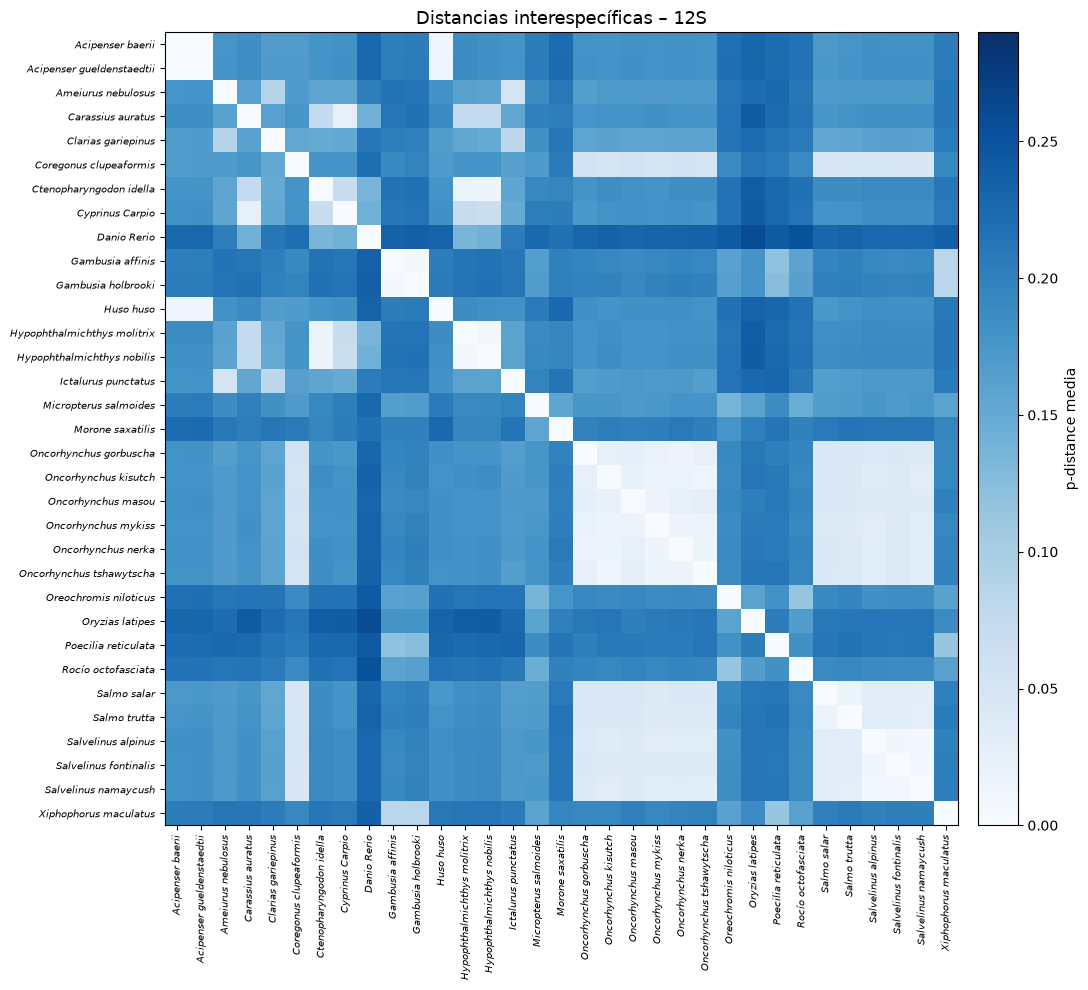

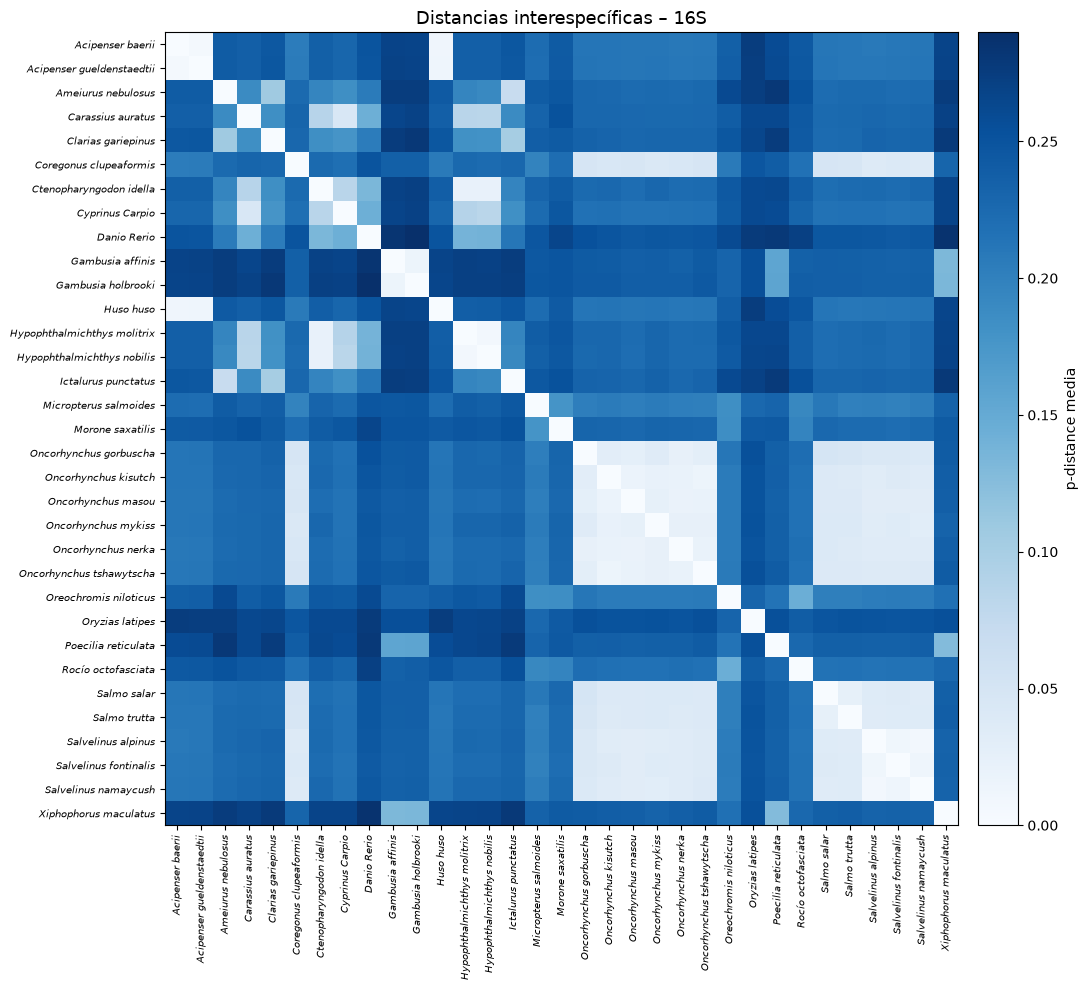

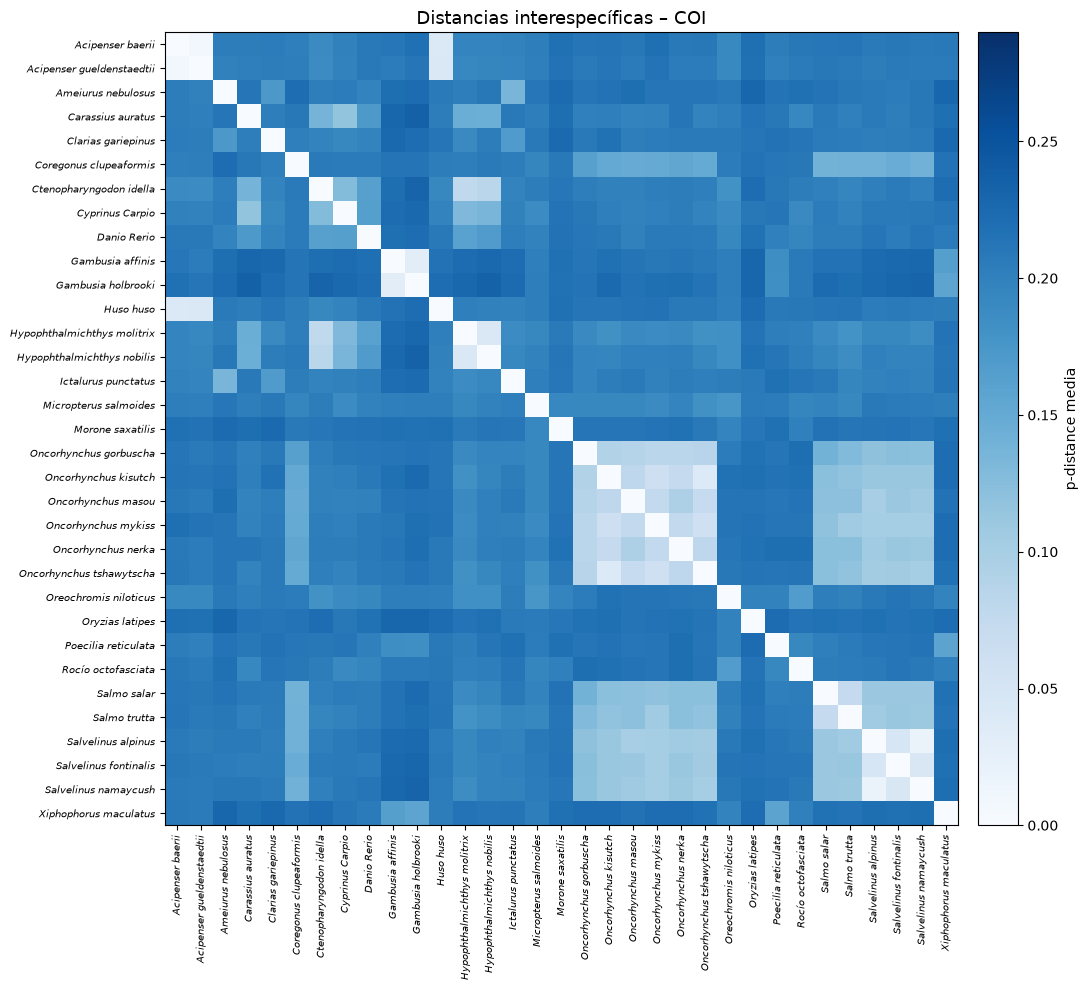

In [51]:
graficar_matriz_inter(
    matriz_inter_12S,
    "12S",
    max_inter
)

graficar_matriz_inter(
    matriz_inter_16S,
    "16S",
    max_inter
)

graficar_matriz_inter(
    matriz_inter_COI,
    "COI",
    max_inter
)

In [52]:
def entropia_shannon_columna(columna):

    validos = [
        nt for nt in columna
        if nt in {"A", "T", "G", "C"}
    ]

    if len(validos) == 0:
        return np.nan

    valores, conteos = np.unique(
        validos,
        return_counts=True
    )

    frecuencias = conteos / conteos.sum()

    entropia = -np.sum(
        frecuencias * np.log2(frecuencias)
    )

    return entropia

In [53]:
resultados_entropia = []

for gen, grupo in df_alineado.groupby("gen"):

    secuencias = grupo["secuencia"].tolist()

    longitud = len(secuencias[0])

    for posicion in range(longitud):

        columna = [
            seq[posicion]
            for seq in secuencias
        ]

        H = entropia_shannon_columna(
            columna
        )

        resultados_entropia.append({
            "gen": gen,
            "posicion": posicion + 1,
            "entropia_shannon": H
        })

df_entropia = pd.DataFrame(
    resultados_entropia
)

df_entropia.head()

,gen,posicion,entropia_shannon
0,12S,1,0.170331
1,12S,2,-0.000000
2,12S,3,-0.000000
3,12S,4,-0.000000
4,12S,5,-0.000000


In [54]:
df_entropia.to_csv(
    RESULTADOS / "entropia_shannon_por_posicion.csv",
    index=False
)

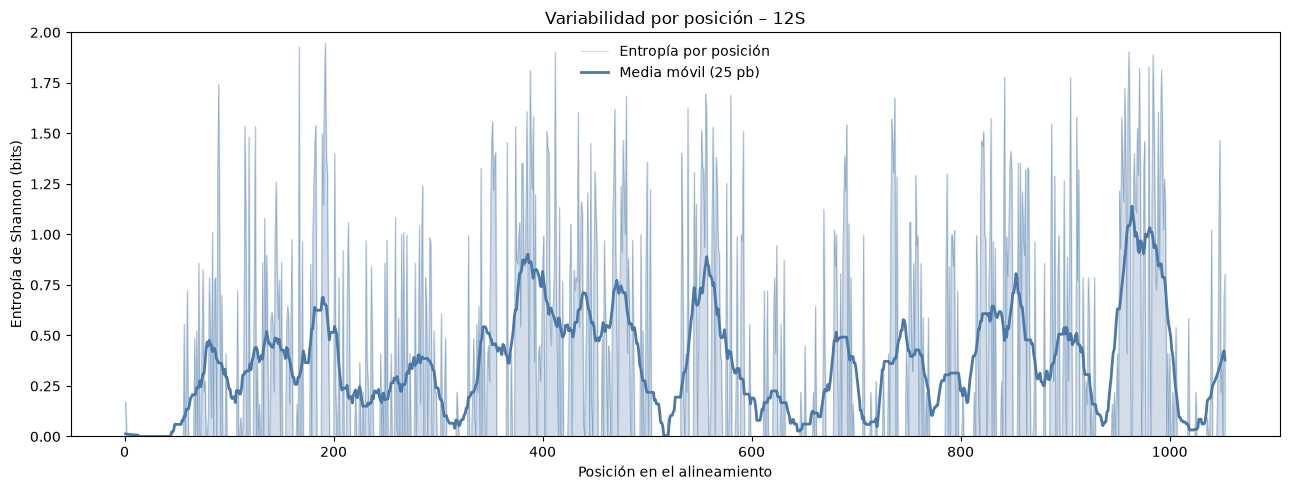

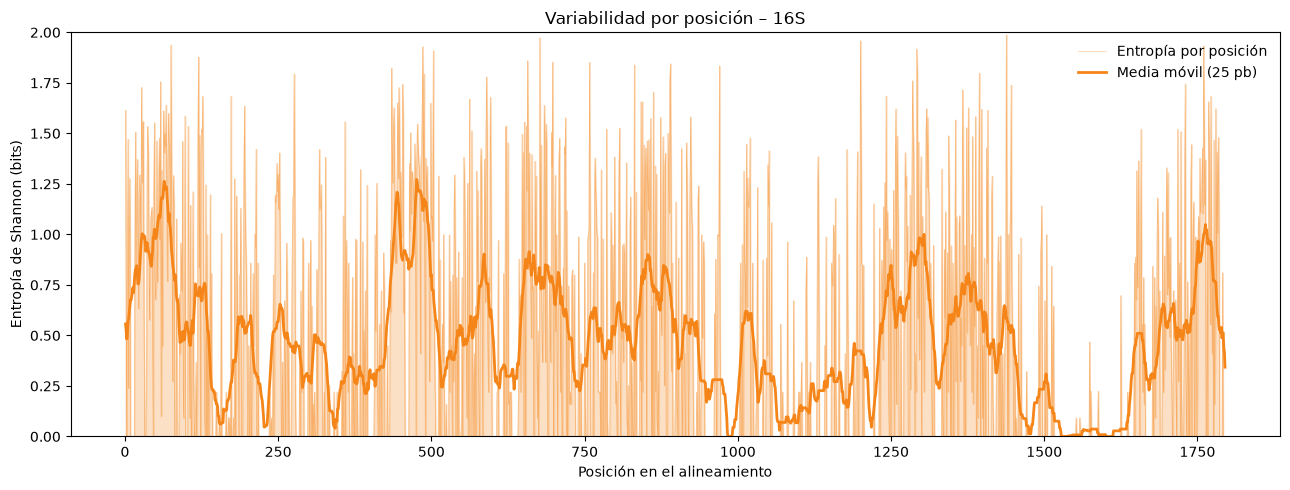

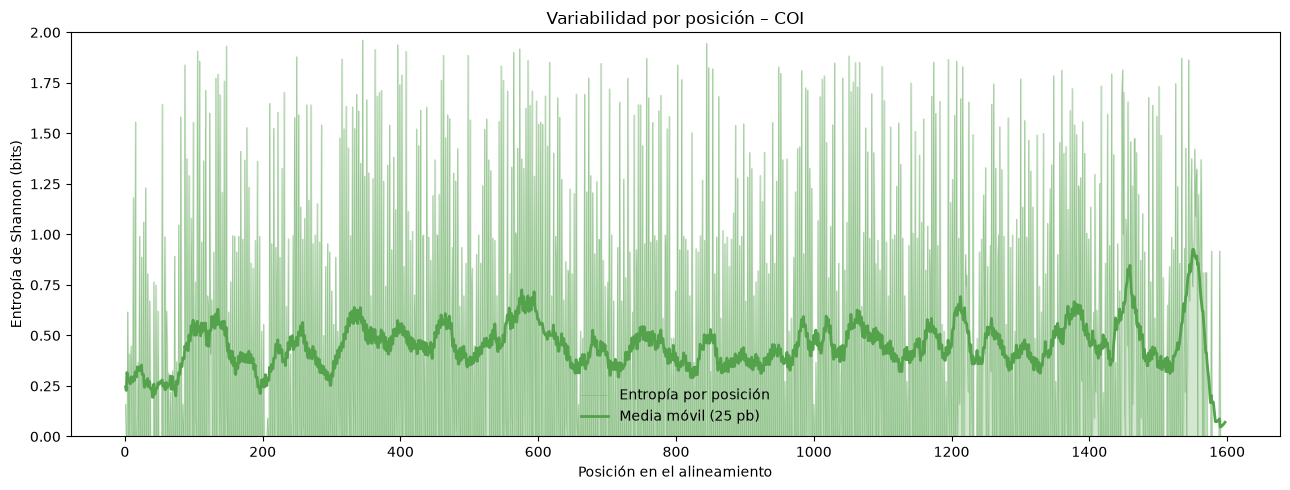

In [55]:
ventana = 25

for gen in ["12S", "16S", "COI"]:

    datos = (
        df_entropia[df_entropia["gen"] == gen]
        .copy()
        .reset_index(drop=True)
    )

    # Media móvil para resaltar regiones de variabilidad sostenida
    datos["entropia_suavizada"] = (
        datos["entropia_shannon"]
        .rolling(
            window=ventana,
            center=True,
            min_periods=1
        )
        .mean()
    )

    fig, ax = plt.subplots(figsize=(13, 5))

    # Área bajo la curva
    ax.fill_between(
        datos["posicion"],
        datos["entropia_shannon"],
        0,
        alpha=0.25,
        color=colores[gen]
    )

    # Entropía original por posición
    ax.plot(
        datos["posicion"],
        datos["entropia_shannon"],
        linewidth=0.45,
        alpha=0.45,
        color=colores[gen],
        label="Entropía por posición"
    )

    # Media móvil
    ax.plot(
        datos["posicion"],
        datos["entropia_suavizada"],
        linewidth=2,
        color=colores[gen],
        label=f"Media móvil ({ventana} pb)"
    )

    ax.set_xlabel("Posición en el alineamiento")
    ax.set_ylabel("Entropía de Shannon (bits)")
    ax.set_title(f"Variabilidad por posición – {gen}")

    # Misma escala en los tres marcadores
    ax.set_ylim(0, 2)

    ax.legend(frameon=False)

    plt.tight_layout()

    plt.savefig(
        FIGURAS / f"entropia_shannon_suavizada_{gen}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        FIGURAS / f"entropia_shannon_suavizada_{gen}.pdf",
        bbox_inches="tight"
    )

    plt.show()

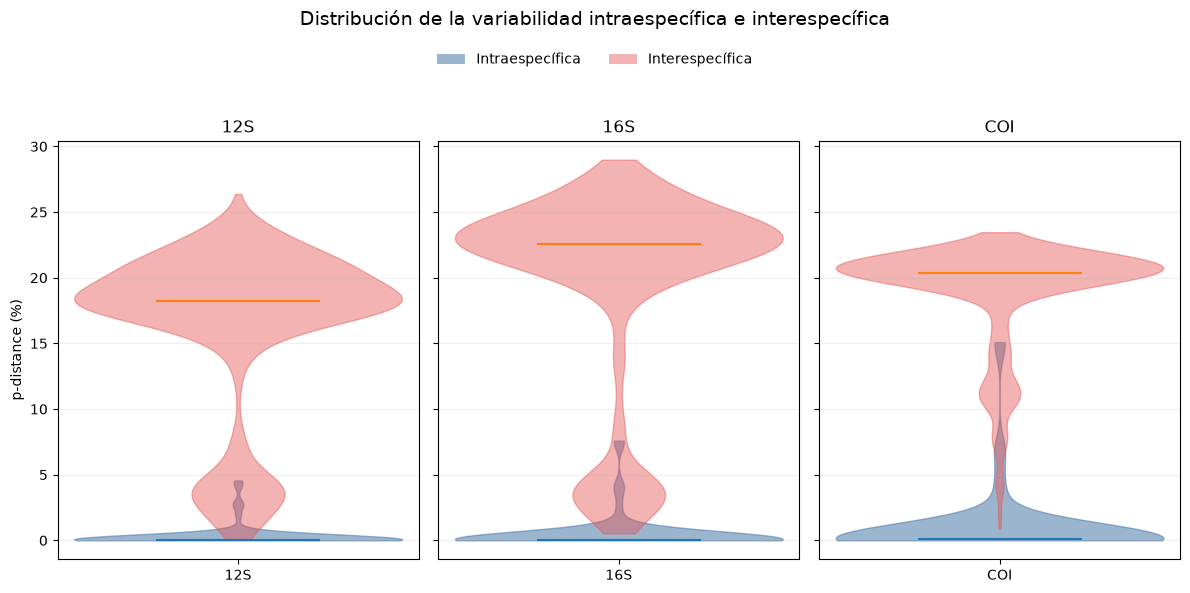

In [56]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 6),
    sharey=True
)

for ax, gen in zip(axes, ["12S", "16S", "COI"]):

    # Pasamos p-distance a porcentaje
    intra = (
        distancias_intra.loc[
            distancias_intra["gen"] == gen,
            "p_distance"
        ]
        .dropna()
        .values * 100
    )

    inter = (
        distancias_inter.loc[
            distancias_inter["gen"] == gen,
            "p_distance"
        ]
        .dropna()
        .values * 100
    )

    # VIOLÍN INTRA
    violin_intra = ax.violinplot(
        [intra],
        positions=[1],
        widths=0.85,
        showmeans=False,
        showmedians=True,
        showextrema=False
    )

    for cuerpo in violin_intra["bodies"]:
        cuerpo.set_facecolor("#4C78A8")
        cuerpo.set_edgecolor("#4C78A8")
        cuerpo.set_alpha(0.55)

    # VIOLÍN INTER EN LA MISMA POSICIÓN
    violin_inter = ax.violinplot(
        [inter],
        positions=[1],
        widths=0.85,
        showmeans=False,
        showmedians=True,
        showextrema=False
    )

    for cuerpo in violin_inter["bodies"]:
        cuerpo.set_facecolor("#E45756")
        cuerpo.set_edgecolor("#E45756")
        cuerpo.set_alpha(0.45)

    ax.set_xticks([1])
    ax.set_xticklabels([gen])

    ax.set_title(gen)

    ax.grid(
        axis="y",
        alpha=0.2
    )

axes[0].set_ylabel("p-distance (%)")

fig.suptitle(
    "Distribución de la variabilidad intraespecífica e interespecífica",
    fontsize=14
)

# Leyenda manual
from matplotlib.patches import Patch

leyenda = [
    Patch(
        facecolor="#4C78A8",
        alpha=0.55,
        label="Intraespecífica"
    ),
    Patch(
        facecolor="#E45756",
        alpha=0.45,
        label="Interespecífica"
    )
]

fig.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=2,
    frameon=False
)

plt.tight_layout(
    rect=[0, 0, 1, 0.88]
)

plt.savefig(
    FIGURAS / "violin_intra_inter_superpuesto.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "violin_intra_inter_superpuesto.pdf",
    bbox_inches="tight"
)

plt.show()

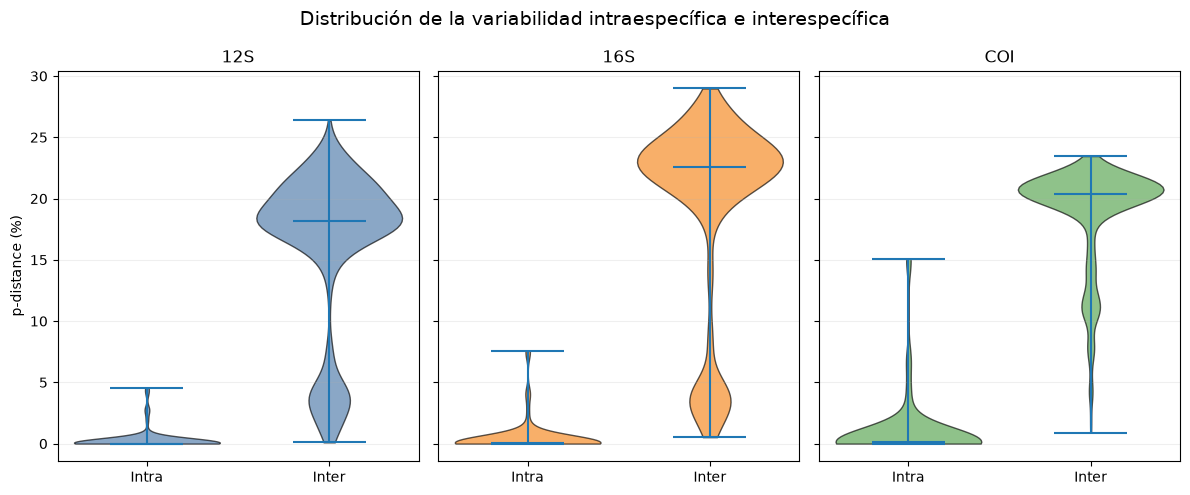

In [57]:
# Preparar los datos en porcentaje
datos_violin = {}

for gen in ["12S", "16S", "COI"]:

    intra = (
        distancias_intra.loc[
            distancias_intra["gen"] == gen,
            "p_distance"
        ]
        .dropna()
        .values * 100
    )

    inter = (
        distancias_inter.loc[
            distancias_inter["gen"] == gen,
            "p_distance"
        ]
        .dropna()
        .values * 100
    )

    datos_violin[gen] = {
        "Intraespecífica": intra,
        "Interespecífica": inter
    }


# Crear figura
fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 5),
    sharey=True
)

for ax, gen in zip(axes, ["12S", "16S", "COI"]):

    intra = datos_violin[gen]["Intraespecífica"]
    inter = datos_violin[gen]["Interespecífica"]

    partes = ax.violinplot(
        [intra, inter],
        positions=[1, 2],
        showmeans=False,
        showmedians=True,
        showextrema=True,
        widths=0.8
    )

    # Usar el color correspondiente al marcador
    for cuerpo in partes["bodies"]:
        cuerpo.set_facecolor(colores[gen])
        cuerpo.set_edgecolor("black")
        cuerpo.set_alpha(0.65)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(
        ["Intra", "Inter"]
    )

    ax.set_title(gen)

    ax.grid(
        axis="y",
        alpha=0.2
    )

axes[0].set_ylabel("p-distance (%)")

fig.suptitle(
    "Distribución de la variabilidad intraespecífica e interespecífica",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURAS / "violin_intra_vs_inter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "violin_intra_vs_inter.pdf",
    bbox_inches="tight"
)

plt.show()

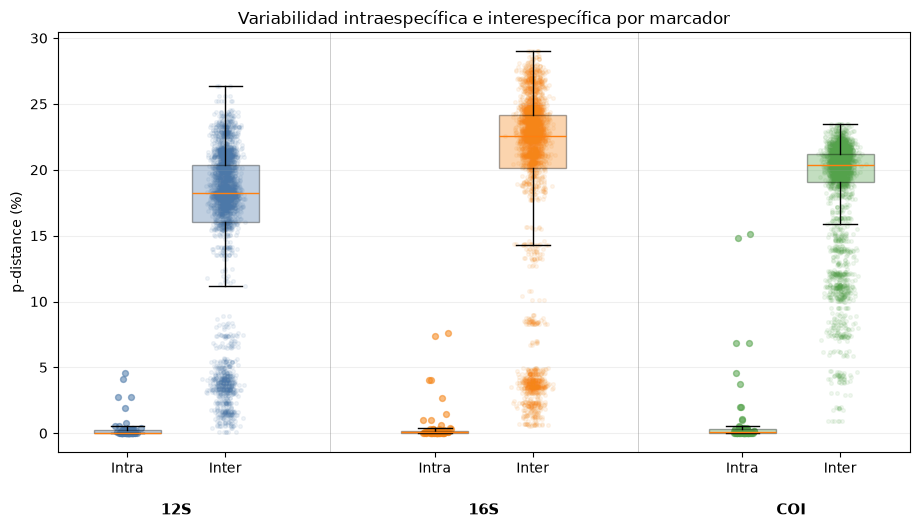

In [58]:
# Preparar datos en porcentaje

genes = ["12S", "16S", "COI"]

datos_grafico = []
posiciones = []
colores_grafico = []
etiquetas = []

pos = 1

for gen in genes:

    intra = (
        distancias_intra.loc[
            distancias_intra["gen"] == gen,
            "p_distance"
        ]
        .dropna()
        .values * 100
    )

    inter = (
        distancias_inter.loc[
            distancias_inter["gen"] == gen,
            "p_distance"
        ]
        .dropna()
        .values * 100
    )

    datos_grafico.extend([intra, inter])

    posiciones.extend([
        pos,
        pos + 0.7
    ])

    colores_grafico.extend([
        colores[gen],
        colores[gen]
    ])

    etiquetas.extend([
        "Intra",
        "Inter"
    ])

    pos += 2.2


# Crear figura
fig, ax = plt.subplots(figsize=(11, 6))

bp = ax.boxplot(
    datos_grafico,
    positions=posiciones,
    widths=0.48,
    patch_artist=True,
    showfliers=False
)

# Colorear cajas
for box, color in zip(
    bp["boxes"],
    colores_grafico
):
    box.set_facecolor(color)
    box.set_alpha(0.35)


# Agregar puntos individuales
rng = np.random.default_rng(42)

for i, (datos, posicion, color) in enumerate(
    zip(
        datos_grafico,
        posiciones,
        colores_grafico
    )
):

    jitter = rng.normal(
        posicion,
        0.045,
        size=len(datos)
    )

    # Menor opacidad para inter porque hay muchos más puntos
    if etiquetas[i] == "Inter":
        alpha = 0.08
        tamaño = 7
    else:
        alpha = 0.55
        tamaño = 18

    ax.scatter(
        jitter,
        datos,
        color=color,
        alpha=alpha,
        s=tamaño
    )


# Etiquetas Intra / Inter
ax.set_xticks(posiciones)

ax.set_xticklabels(
    etiquetas
)


# Nombre de cada marcador debajo de cada pareja
centros = [
    np.mean(posiciones[0:2]),
    np.mean(posiciones[2:4]),
    np.mean(posiciones[4:6])
]

for centro, gen in zip(
    centros,
    genes
):
    ax.text(
        centro,
        -0.12,
        gen,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=11,
        fontweight="bold"
    )


# Separadores visuales
ax.axvline(
    (posiciones[1] + posiciones[2]) / 2,
    color="gray",
    linewidth=0.7,
    alpha=0.4
)

ax.axvline(
    (posiciones[3] + posiciones[4]) / 2,
    color="gray",
    linewidth=0.7,
    alpha=0.4
)


ax.set_ylabel("p-distance (%)")

ax.set_title(
    "Variabilidad intraespecífica e interespecífica por marcador"
)

ax.grid(
    axis="y",
    alpha=0.2
)

plt.subplots_adjust(bottom=0.18)

plt.savefig(
    FIGURAS / "comparacion_variabilidad_intra_inter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "comparacion_variabilidad_intra_inter.pdf",
    bbox_inches="tight"
)

plt.show()

## 5. Capacidad discriminatoria

La capacidad discriminatoria de los marcadores se evaluó mediante el
barcode gap, definido como la diferencia entre la mínima distancia
interespecífica y la máxima distancia intraespecífica para cada especie.

Un barcode gap positivo indica que la distancia entre la especie evaluada
y su especie más próxima es mayor que la máxima variabilidad observada
dentro de la propia especie. Los valores negativos indican solapamiento
entre las distancias intraespecíficas e interespecíficas.

Las especies representadas por una única secuencia fueron consideradas
no evaluables debido a que no es posible estimar su variabilidad
intraespecífica.

In [71]:
intra_especie = (
    distancias_intra
    .groupby(["gen", "especie"])["p_distance"]
    .mean()
    .reset_index(name="variabilidad_intra")
)

intra_especie.head()

,gen,especie,variabilidad_intra
0,12S,Acipenser baerii,0.000000
1,12S,Acipenser gueldenstaedtii,0.000000
2,12S,Ameiurus nebulosus,0.003472
3,12S,Carassius auratus,0.000000
4,12S,Coregonus clupeaformis,0.002112


In [73]:
inter_1 = distancias_inter[
    ["gen", "especie_1", "p_distance"]
].rename(
    columns={"especie_1": "especie"}
)

inter_2 = distancias_inter[
    ["gen", "especie_2", "p_distance"]
].rename(
    columns={"especie_2": "especie"}
)

inter_largo = pd.concat(
    [inter_1, inter_2],
    ignore_index=True
)

In [74]:
inter_especie = (
    inter_largo
    .groupby(["gen", "especie"])["p_distance"]
    .mean()
    .reset_index(name="variabilidad_inter")
)

inter_especie.head()

,gen,especie,variabilidad_inter
0,12S,Acipenser baerii,0.181018
1,12S,Acipenser gueldenstaedtii,0.179616
2,12S,Ameiurus nebulosus,0.174804
3,12S,Carassius auratus,0.169359
4,12S,Clarias gariepinus,0.166399


In [76]:
capacidad_discriminatoria = pd.merge(
    intra_especie,
    inter_especie,
    on=["gen", "especie"],
    how="outer"
)

capacidad_discriminatoria["diferencia"] = (
    capacidad_discriminatoria["variabilidad_inter"]
    -
    capacidad_discriminatoria["variabilidad_intra"]
)

capacidad_discriminatoria.head(20)

,gen,especie,variabilidad_intra,variabilidad_inter,diferencia
0,12S,Acipenser baerii,0.000000,0.181018,0.181018
1,12S,Acipenser gueldenstaedtii,0.000000,0.179616,0.179616
2,12S,Ameiurus nebulosus,0.003472,0.174804,0.171332
3,12S,Carassius auratus,0.000000,0.169359,0.169359
4,12S,Clarias gariepinus,NaN,0.166399,NaN
5,12S,Coregonus clupeaformis,0.002112,0.132916,0.130804
6,12S,Ctenopharyngodon idella,0.002088,0.166138,0.164050
7,12S,Cyprinus Carpio,0.000000,0.168256,0.168256
8,12S,Danio Rerio,0.000000,0.213831,0.213831
9,12S,Gambusia affinis,0.000000,0.188434,0.188434


In [77]:
matriz_discriminacion = (
    capacidad_discriminatoria
    .pivot(
        index="especie",
        columns="gen",
        values="diferencia"
    )
    .reindex(columns=["12S", "16S", "COI"])
)

matriz_discriminacion.head()

gen,12S,16S,COI
especie,,,
Acipenser baerii,0.181018,0.218922,0.197366
Acipenser gueldenstaedtii,0.179616,0.217300,0.192789
Ameiurus nebulosus,0.171332,0.215100,0.195090
Carassius auratus,0.169359,0.207439,0.196154
Clarias gariepinus,NaN,NaN,NaN


In [78]:
matriz_discriminacion_pct = matriz_discriminacion * 100

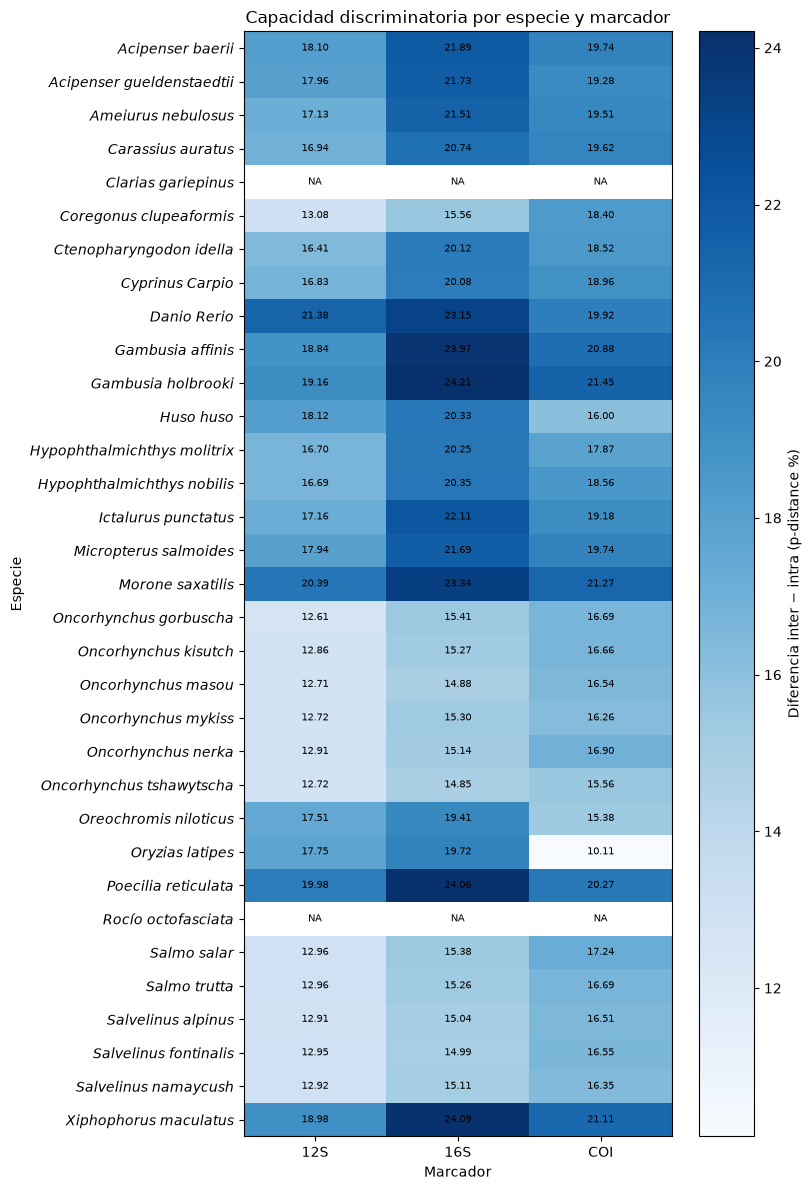

In [79]:
fig, ax = plt.subplots(figsize=(8, 12))

datos = matriz_discriminacion_pct.values

im = ax.imshow(
    datos,
    aspect="auto",
    cmap="Blues"
)

ax.set_xticks(range(len(matriz_discriminacion_pct.columns)))
ax.set_xticklabels(matriz_discriminacion_pct.columns)

ax.set_yticks(range(len(matriz_discriminacion_pct.index)))
ax.set_yticklabels(
    matriz_discriminacion_pct.index,
    fontstyle="italic"
)

# Valores dentro de las celdas
for i in range(datos.shape[0]):
    for j in range(datos.shape[1]):

        valor = datos[i, j]

        if pd.notna(valor):
            ax.text(
                j, i,
                f"{valor:.2f}",
                ha="center",
                va="center",
                fontsize=7
            )
        else:
            ax.text(
                j, i,
                "NA",
                ha="center",
                va="center",
                fontsize=7
            )

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Diferencia inter − intra (p-distance %)")

ax.set_xlabel("Marcador")
ax.set_ylabel("Especie")
ax.set_title(
    "Capacidad discriminatoria por especie y marcador"
)

plt.tight_layout()

plt.savefig(
    FIGURAS / "capacidad_discriminatoria_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "capacidad_discriminatoria_heatmap.pdf",
    bbox_inches="tight"
)

plt.show()

In [81]:
capacidad_discriminatoria.to_csv(
    RESULTADOS / "capacidad_discriminatoria_por_especie.csv",
    index=False
)

matriz_discriminacion.to_csv(
    RESULTADOS / "matriz_capacidad_discriminatoria.csv"
)

In [80]:
promedio_discriminacion = (
    capacidad_discriminatoria
    .groupby("gen")["diferencia"]
    .mean()
    .reindex(["12S", "16S", "COI"])
    .reset_index(name="diferencia_media")
)

# Para expresarlo como porcentaje
promedio_discriminacion["diferencia_media_pct"] = (
    promedio_discriminacion["diferencia_media"] * 100
)

promedio_discriminacion

,gen,diferencia_media,diferencia_media_pct
0,12S,0.160730,16.073027
1,16S,0.191923,19.192333
2,COI,0.179901,17.990100


In [82]:
promedio_discriminacion.to_csv(
    RESULTADOS / "capacidad_discriminatoria_promedio_marcadores.csv",
    index=False
)

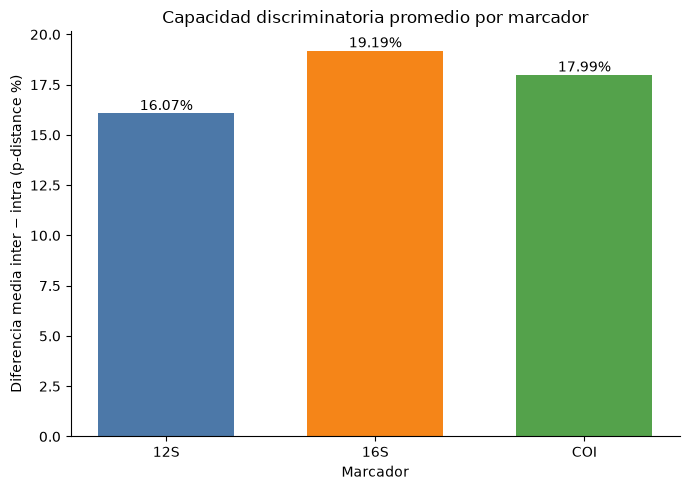

In [83]:
fig, ax = plt.subplots(figsize=(7, 5))

genes = promedio_discriminacion["gen"]
valores = promedio_discriminacion["diferencia_media_pct"]

barras = ax.bar(
    genes,
    valores,
    color=[colores[gen] for gen in genes],
    width=0.65
)

# Mostrar valor sobre cada barra
for barra, valor in zip(barras, valores):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_ylabel("Diferencia media inter − intra (p-distance %)")
ax.set_xlabel("Marcador")
ax.set_title("Capacidad discriminatoria promedio por marcador")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURAS / "capacidad_discriminatoria_promedio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "capacidad_discriminatoria_promedio.pdf",
    bbox_inches="tight"
)

plt.show()

In [86]:
VENTANA = 25
PASO = 1

In [87]:
def calcular_p_distance_ventana(seq1, seq2, inicio, fin):
    
    validos = {"A", "T", "G", "C"}

    diferencias = 0
    sitios_comparados = 0

    ventana1 = seq1[inicio:fin]
    ventana2 = seq2[inicio:fin]

    for nt1, nt2 in zip(ventana1, ventana2):

        if nt1 in validos and nt2 in validos:

            sitios_comparados += 1

            if nt1 != nt2:
                diferencias += 1

    if sitios_comparados == 0:
        return np.nan

    return diferencias / sitios_comparados

In [88]:
from itertools import combinations

resultados_ventanas = []

for gen in ["12S", "16S", "COI"]:

    print(f"Procesando {gen}...")

    datos_gen = (
        df_alineado[
            df_alineado["gen"] == gen
        ]
        .reset_index(drop=True)
    )

    longitud_alineamiento = len(
        datos_gen.loc[0, "secuencia"]
    )

    especies = sorted(
        datos_gen["especie"].unique()
    )

    # Recorremos ventanas de 25 pb
    for inicio in range(
        0,
        longitud_alineamiento - VENTANA + 1,
        PASO
    ):

        fin = inicio + VENTANA

        # Cada especie será considerada como objetivo
        for especie in especies:

            target = datos_gen[
                datos_gen["especie"] == especie
            ].reset_index(drop=True)

            no_target = datos_gen[
                datos_gen["especie"] != especie
            ].reset_index(drop=True)

            # ==========================================
            # VARIABILIDAD INTRAESPECÍFICA
            # ==========================================

            distancias_intra_ventana = []

            if len(target) >= 2:

                for i, j in combinations(
                    range(len(target)),
                    2
                ):

                    p = calcular_p_distance_ventana(
                        target.loc[i, "secuencia"],
                        target.loc[j, "secuencia"],
                        inicio,
                        fin
                    )

                    if pd.notna(p):
                        distancias_intra_ventana.append(p)

            if len(distancias_intra_ventana) > 0:
                variabilidad_intra = np.mean(
                    distancias_intra_ventana
                )
            else:
                variabilidad_intra = np.nan

            # ==========================================
            # VARIABILIDAD INTERESPECÍFICA
            # ==========================================

            distancias_inter_ventana = []

            for i in range(len(target)):

                for j in range(len(no_target)):

                    p = calcular_p_distance_ventana(
                        target.loc[i, "secuencia"],
                        no_target.loc[j, "secuencia"],
                        inicio,
                        fin
                    )

                    if pd.notna(p):
                        distancias_inter_ventana.append(p)

            if len(distancias_inter_ventana) > 0:
                variabilidad_inter = np.mean(
                    distancias_inter_ventana
                )
            else:
                variabilidad_inter = np.nan

            # ==========================================
            # DIFERENCIA INTER - INTRA
            # ==========================================

            if (
                pd.notna(variabilidad_intra)
                and pd.notna(variabilidad_inter)
            ):

                diferencia = (
                    variabilidad_inter
                    - variabilidad_intra
                )

            else:
                diferencia = np.nan

            resultados_ventanas.append({
                "gen": gen,
                "especie": especie,

                # posiciones comenzando en 1
                "inicio": inicio + 1,
                "fin": fin,

                "variabilidad_intra": variabilidad_intra,
                "variabilidad_inter": variabilidad_inter,
                "diferencia": diferencia
            })

Procesando 12S...
Procesando 16S...
Procesando COI...


In [89]:
ventanas_variabilidad = pd.DataFrame(
    resultados_ventanas
)

ventanas_variabilidad.head(20)

,gen,especie,inicio,fin,variabilidad_intra,variabilidad_inter,diferencia
0,12S,Acipenser baerii,1,25,0.0,0.008130,0.008130
1,12S,Acipenser gueldenstaedtii,1,25,0.0,0.008032,0.008032
2,12S,Ameiurus nebulosus,1,25,0.0,0.008130,0.008130
3,12S,Carassius auratus,1,25,0.0,0.008130,0.008130
4,12S,Clarias gariepinus,1,25,NaN,0.007937,NaN
5,12S,Coregonus clupeaformis,1,25,0.0,0.008130,0.008130
6,12S,Ctenopharyngodon idella,1,25,0.0,0.008032,0.008032
7,12S,Cyprinus Carpio,1,25,0.0,0.008130,0.008130
8,12S,Danio Rerio,1,25,0.0,0.008130,0.008130
9,12S,Gambusia affinis,1,25,0.0,0.008032,0.008032


In [90]:
ventanas_variabilidad_pct = (
    ventanas_variabilidad.copy()
)

columnas = [
    "variabilidad_intra",
    "variabilidad_inter",
    "diferencia"
]

ventanas_variabilidad_pct[columnas] = (
    ventanas_variabilidad_pct[columnas]
    * 100
)

ventanas_variabilidad_pct.head(20)

,gen,especie,inicio,fin,variabilidad_intra,variabilidad_inter,diferencia
0,12S,Acipenser baerii,1,25,0.0,0.813008,0.813008
1,12S,Acipenser gueldenstaedtii,1,25,0.0,0.803213,0.803213
2,12S,Ameiurus nebulosus,1,25,0.0,0.813008,0.813008
3,12S,Carassius auratus,1,25,0.0,0.813008,0.813008
4,12S,Clarias gariepinus,1,25,NaN,0.793651,NaN
5,12S,Coregonus clupeaformis,1,25,0.0,0.813008,0.813008
6,12S,Ctenopharyngodon idella,1,25,0.0,0.803213,0.803213
7,12S,Cyprinus Carpio,1,25,0.0,0.813008,0.813008
8,12S,Danio Rerio,1,25,0.0,0.813008,0.813008
9,12S,Gambusia affinis,1,25,0.0,0.803213,0.803213


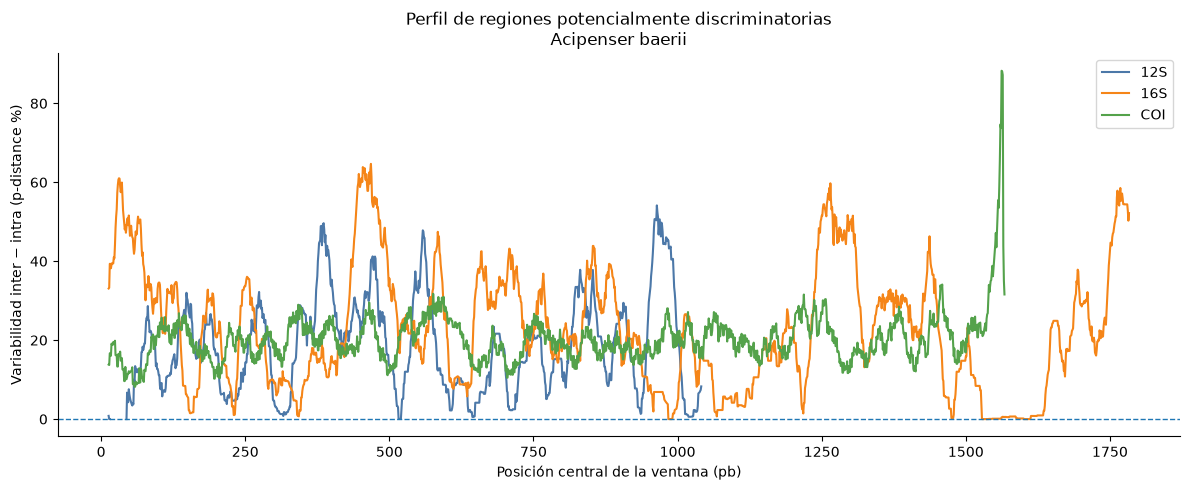

In [91]:
especie_ejemplo = (
    ventanas_variabilidad[
        "especie"
    ].dropna().iloc[0]
)

fig, ax = plt.subplots(figsize=(12, 5))

for gen in ["12S", "16S", "COI"]:

    datos = ventanas_variabilidad[
        (ventanas_variabilidad["gen"] == gen) &
        (ventanas_variabilidad["especie"] == especie_ejemplo)
    ].copy()

    datos["centro"] = (
        datos["inicio"] +
        datos["fin"]
    ) / 2

    ax.plot(
        datos["centro"],
        datos["diferencia"] * 100,
        label=gen,
        color=colores[gen],
        linewidth=1.5
    )

ax.axhline(
    0,
    linewidth=1,
    linestyle="--"
)

ax.set_xlabel(
    "Posición central de la ventana (pb)"
)

ax.set_ylabel(
    "Variabilidad inter − intra (p-distance %)"
)

ax.set_title(
    f"Perfil de regiones potencialmente discriminatorias\n"
    f"{especie_ejemplo}"
)

ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [92]:
ventanas_variabilidad.to_csv(
    RESULTADOS / "variabilidad_ventanas_25pb.csv",
    index=False
)

In [93]:
ventanas_candidatas = ventanas_variabilidad.copy()

ventanas_candidatas["umbral_p90"] = (
    ventanas_candidatas
    .groupby(["gen", "especie"])["diferencia"]
    .transform(lambda x: x.quantile(0.90))
)

ventanas_candidatas["candidata"] = (
    ventanas_candidatas["diferencia"]
    >= ventanas_candidatas["umbral_p90"]
)

ventanas_candidatas.head()

,gen,especie,inicio,fin,variabilidad_intra,variabilidad_inter,diferencia,umbral_p90,candidata
0,12S,Acipenser baerii,1,25,0.0,0.008130,0.008130,0.344900,False
1,12S,Acipenser gueldenstaedtii,1,25,0.0,0.008032,0.008032,0.342479,False
2,12S,Ameiurus nebulosus,1,25,0.0,0.008130,0.008130,0.351415,False
3,12S,Carassius auratus,1,25,0.0,0.008130,0.008130,0.322588,False
4,12S,Clarias gariepinus,1,25,NaN,0.007937,NaN,NaN,False


In [94]:
especie_ejemplo = "Oreochromis niloticus"

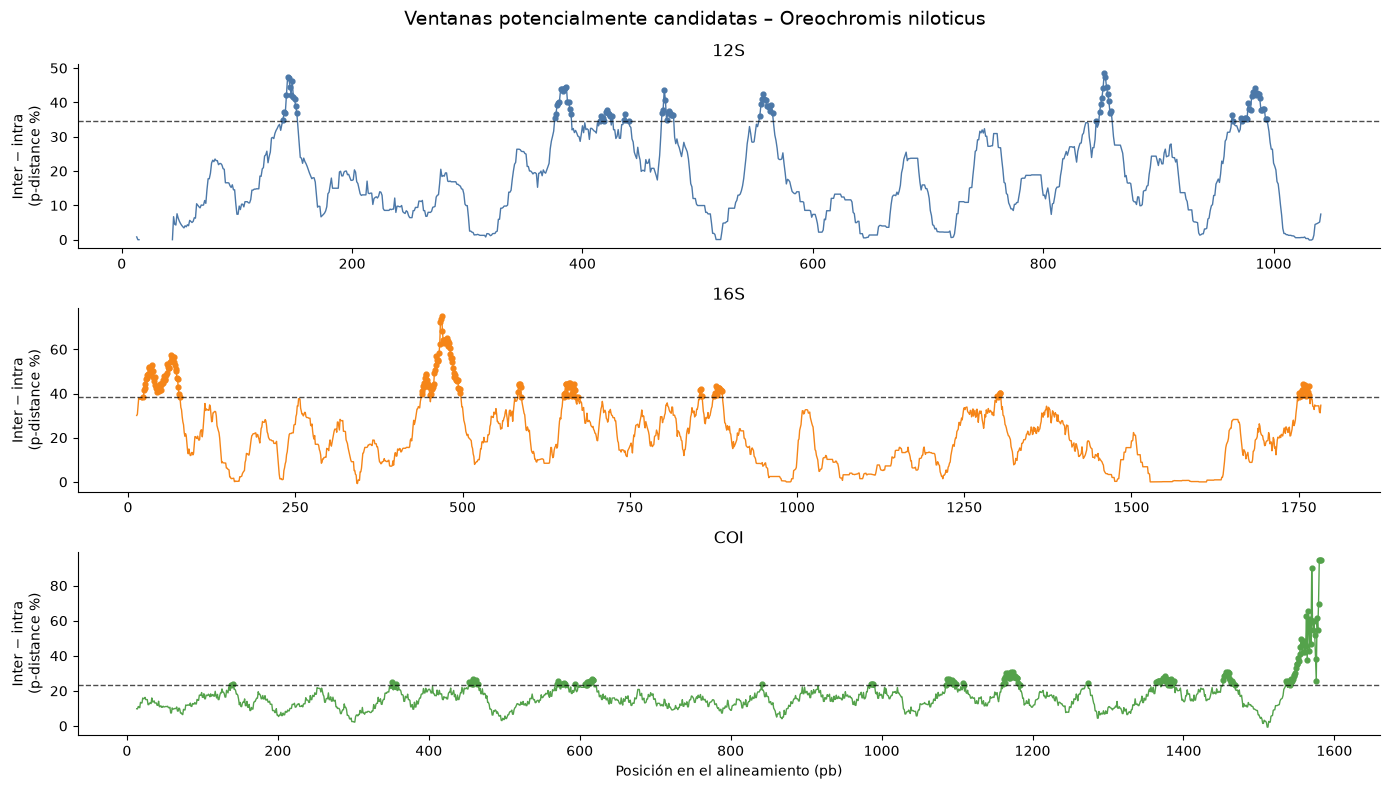

In [95]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 8),
    sharex=False
)

for ax, gen in zip(axes, ["12S", "16S", "COI"]):

    datos = ventanas_candidatas[
        (ventanas_candidatas["gen"] == gen) &
        (ventanas_candidatas["especie"] == especie_ejemplo)
    ].copy()

    datos["centro"] = (
        datos["inicio"] + datos["fin"]
    ) / 2

    # Perfil completo
    ax.plot(
        datos["centro"],
        datos["diferencia"] * 100,
        color=colores[gen],
        linewidth=1
    )

    # Umbral P90
    umbral = datos["umbral_p90"].iloc[0] * 100

    ax.axhline(
        umbral,
        linestyle="--",
        linewidth=1,
        color="black",
        alpha=0.7
    )

    # Ventanas candidatas
    candidatas = datos[
        datos["candidata"]
    ]

    ax.scatter(
        candidatas["centro"],
        candidatas["diferencia"] * 100,
        color=colores[gen],
        s=12
    )

    ax.set_ylabel(
        "Inter − intra\n(p-distance %)"
    )

    ax.set_title(gen)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xlabel(
    "Posición en el alineamiento (pb)"
)

fig.suptitle(
    f"Ventanas potencialmente candidatas – {especie_ejemplo}",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [96]:
def fusionar_ventanas(datos):

    # Solo ventanas consideradas candidatas
    datos = (
        datos[datos["candidata"]]
        .sort_values("inicio")
    )

    if datos.empty:
        return []

    regiones = []

    inicio_region = datos.iloc[0]["inicio"]
    fin_region = datos.iloc[0]["fin"]

    for _, fila in datos.iloc[1:].iterrows():

        inicio = fila["inicio"]
        fin = fila["fin"]

        # Si la nueva ventana se superpone o continúa
        # inmediatamente después de la región actual
        if inicio <= fin_region + 1:

            fin_region = max(
                fin_region,
                fin
            )

        else:

            regiones.append(
                (inicio_region, fin_region)
            )

            inicio_region = inicio
            fin_region = fin

    # Guardar última región
    regiones.append(
        (inicio_region, fin_region)
    )

    return regiones

In [97]:
regiones_candidatas = []

for (gen, especie), grupo in ventanas_candidatas.groupby(
    ["gen", "especie"]
):

    regiones = fusionar_ventanas(grupo)

    for numero, (inicio, fin) in enumerate(
        regiones,
        start=1
    ):

        regiones_candidatas.append({
            "gen": gen,
            "especie": especie,
            "region": numero,
            "inicio": int(inicio),
            "fin": int(fin),
            "longitud": int(fin - inicio + 1)
        })


regiones_candidatas = pd.DataFrame(
    regiones_candidatas
)

regiones_candidatas.head(20)

,gen,especie,region,inicio,fin,longitud
0,12S,Acipenser baerii,1,362,412,51
1,12S,Acipenser baerii,2,455,491,37
2,12S,Acipenser baerii,3,533,577,45
3,12S,Acipenser baerii,4,818,866,49
4,12S,Acipenser baerii,5,942,1005,64
5,12S,Acipenser gueldenstaedtii,1,363,412,50
6,12S,Acipenser gueldenstaedtii,2,455,491,37
7,12S,Acipenser gueldenstaedtii,3,533,577,45
8,12S,Acipenser gueldenstaedtii,4,818,866,49
9,12S,Acipenser gueldenstaedtii,5,941,1005,65


In [98]:
regiones_candidatas.to_csv(
    RESULTADOS / "regiones_candidatas.csv",
    index=False
)

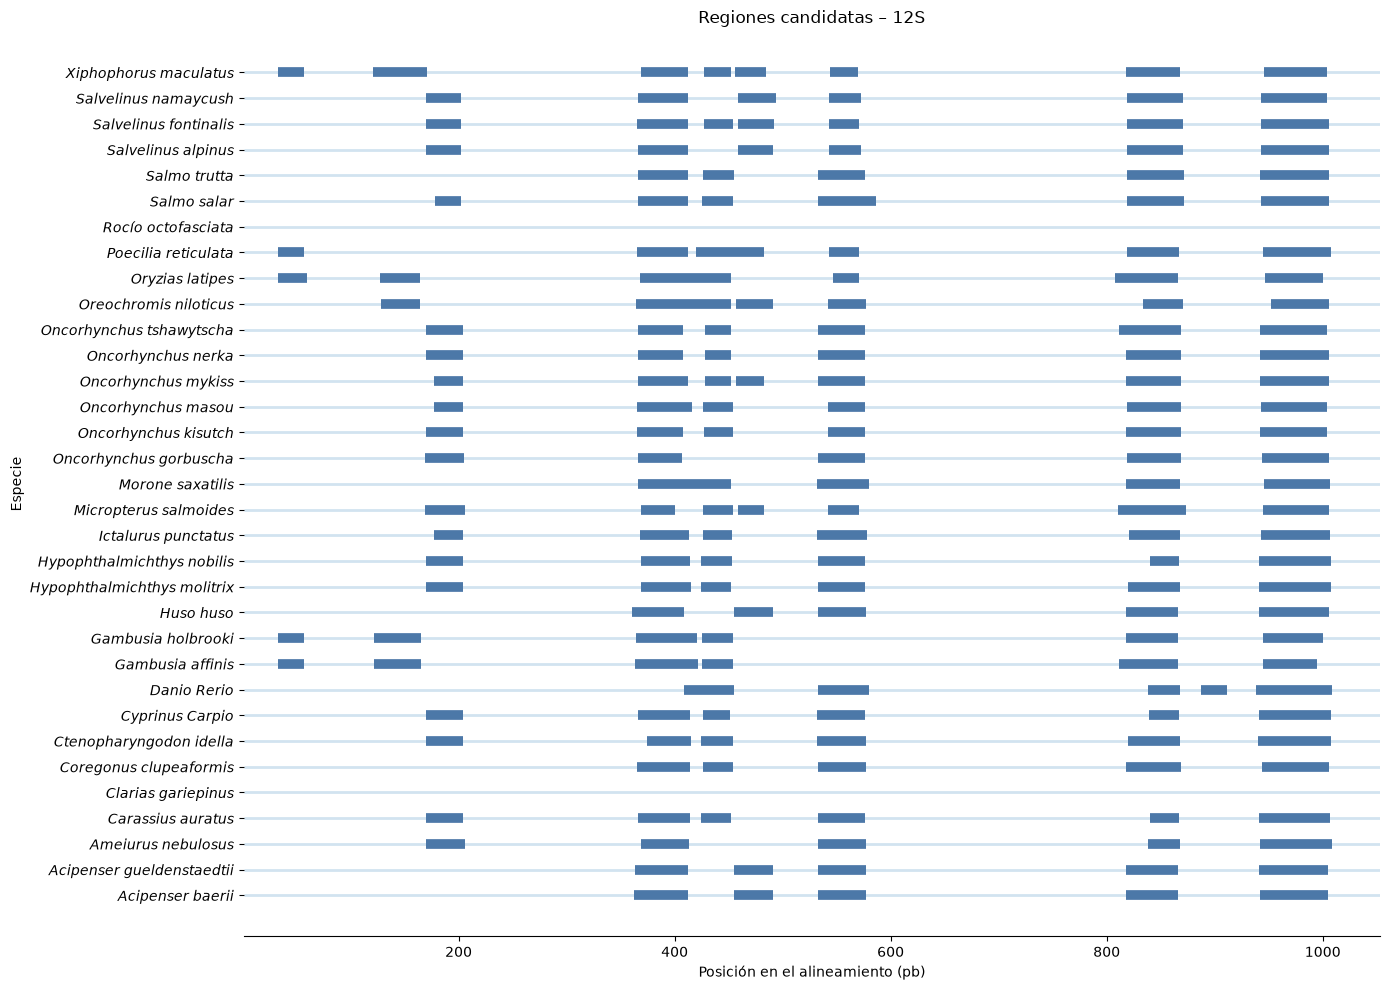

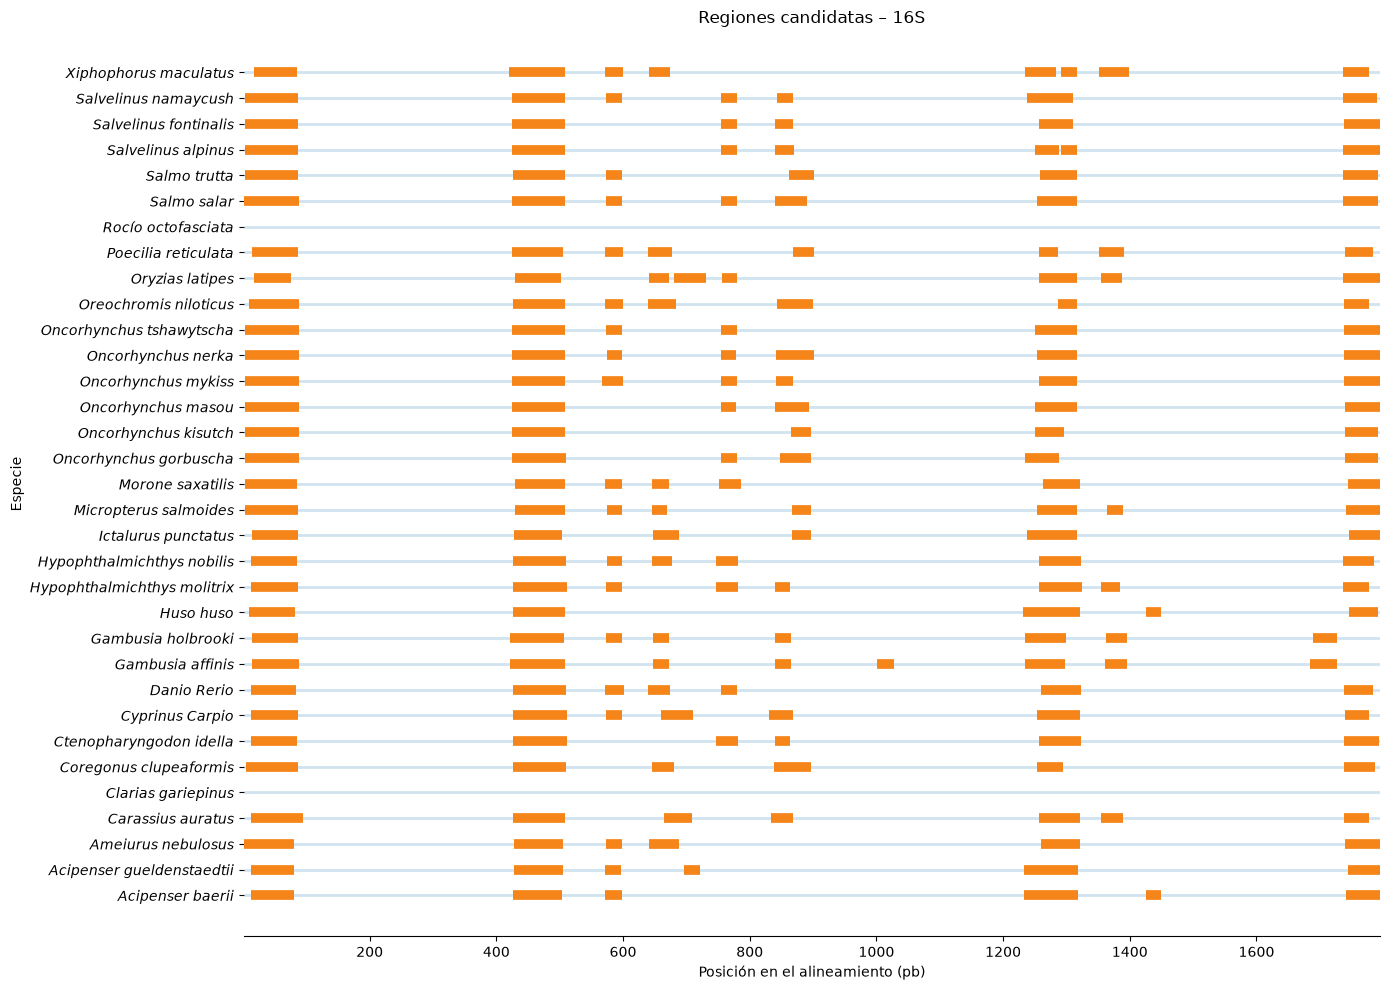

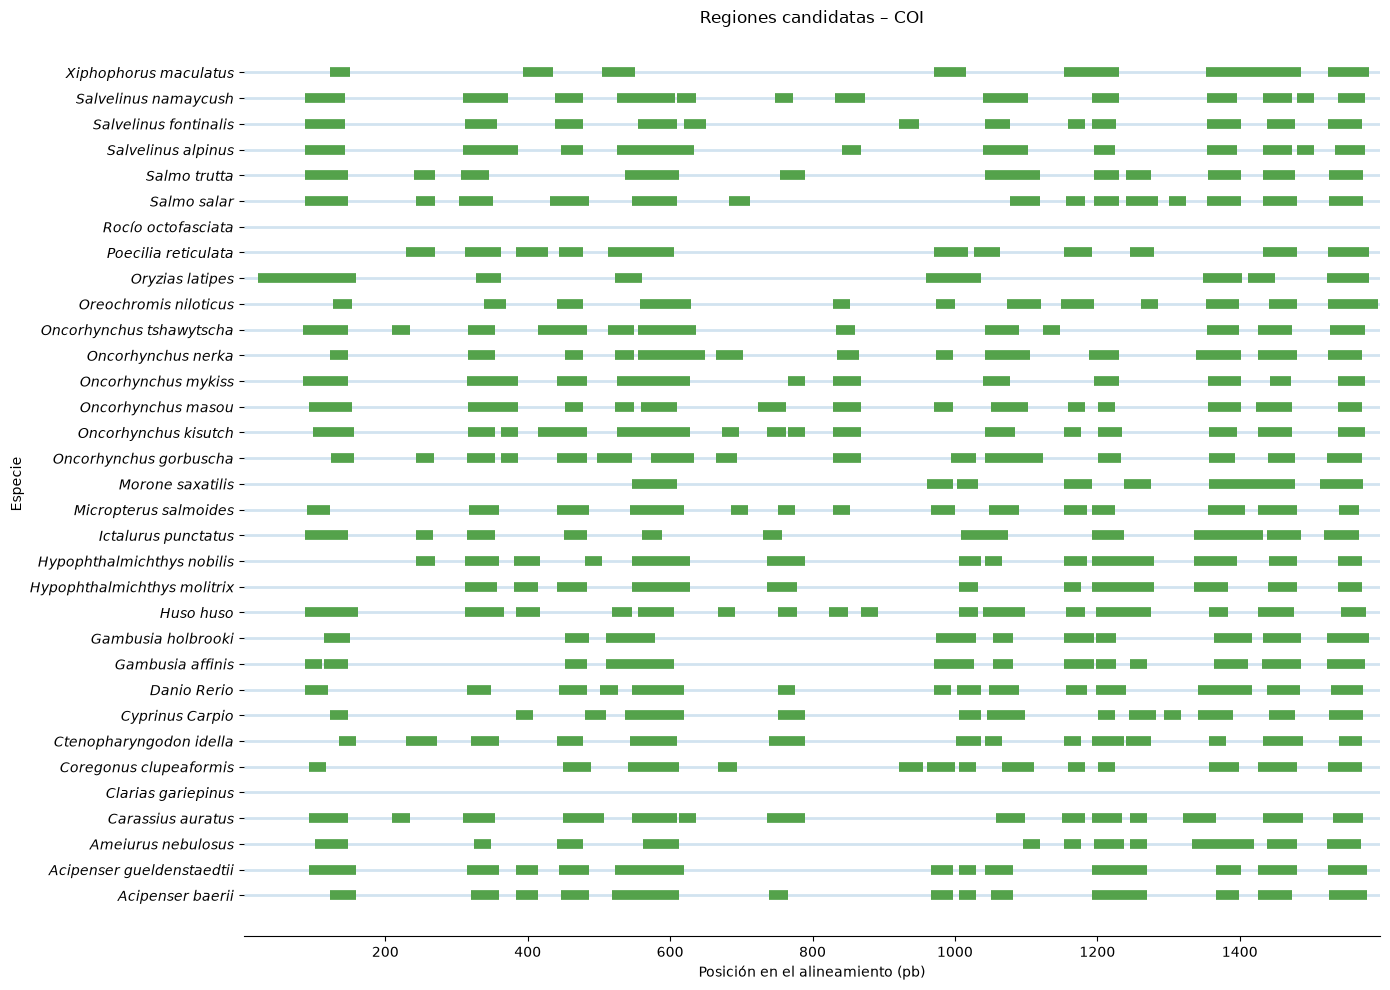

In [100]:
for gen in ["12S", "16S", "COI"]:

    datos_gen = regiones_candidatas[
        regiones_candidatas["gen"] == gen
    ]

    especies = sorted(
        df_alineado[
            df_alineado["gen"] == gen
        ]["especie"].unique()
    )

    longitud_gen = len(
        df_alineado[
            df_alineado["gen"] == gen
        ].iloc[0]["secuencia"]
    )

    fig, ax = plt.subplots(
        figsize=(14, 10)
    )

    for y, especie in enumerate(especies):

        ax.hlines(
            y,
            1,
            longitud_gen,
            linewidth=2,
            alpha=0.20
        )

        regiones = datos_gen[
            datos_gen["especie"] == especie
        ]

        for _, region in regiones.iterrows():

            ax.hlines(
                y,
                region["inicio"],
                region["fin"],
                linewidth=7,
                color=colores[gen]
            )

    ax.set_yticks(
        range(len(especies))
    )

    ax.set_yticklabels(
        especies,
        fontstyle="italic"
    )

    ax.set_xlim(
        1,
        longitud_gen
    )

    ax.set_xlabel(
        "Posición en el alineamiento (pb)"
    )

    ax.set_ylabel(
        "Especie"
    )

    ax.set_title(
        f"Regiones candidatas – {gen}"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    plt.tight_layout()

    plt.savefig(
        FIGURAS / f"regiones_candidatas_{gen}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        FIGURAS / f"regiones_candidatas_{gen}.pdf",
        bbox_inches="tight"
    )

    plt.show()

In [101]:
resumen_regiones = (
    regiones_candidatas
    .groupby("gen")["longitud"]
    .agg(
        n_regiones="count",
        longitud_media="mean",
        longitud_mediana="median",
        longitud_minima="min",
        longitud_maxima="max"
    )
    .reindex(["12S", "16S", "COI"])
    .reset_index()
)

resumen_regiones

,gen,n_regiones,longitud_media,longitud_mediana,longitud_minima,longitud_maxima
0,12S,181,44.823204,45.0,25,89
1,16S,209,54.129187,54.0,25,90
2,COI,376,45.015957,40.0,25,139


In [102]:
regiones_por_especie = (
    regiones_candidatas
    .groupby(["gen", "especie"])
    .size()
    .reset_index(name="n_regiones")
)

regiones_por_especie.head()

,gen,especie,n_regiones
0,12S,Acipenser baerii,5
1,12S,Acipenser gueldenstaedtii,5
2,12S,Ameiurus nebulosus,5
3,12S,Carassius auratus,6
4,12S,Coregonus clupeaformis,5


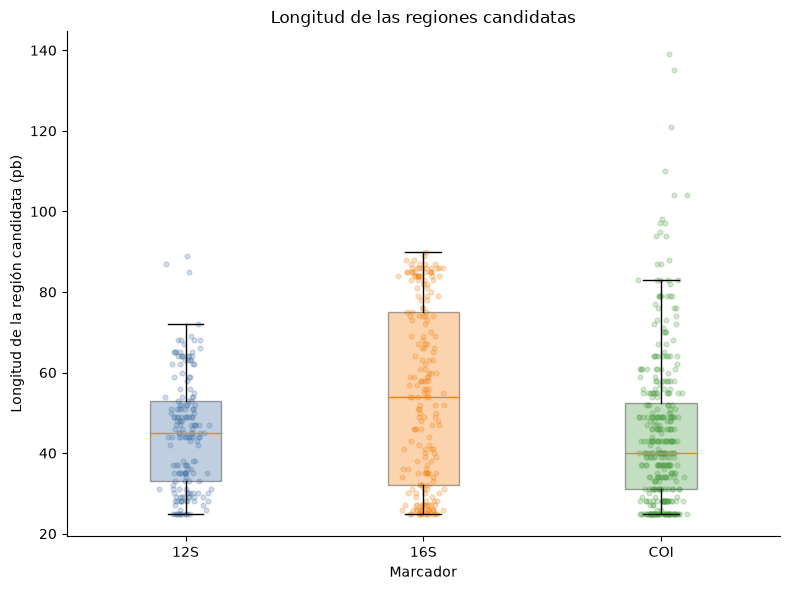

In [105]:
fig, ax = plt.subplots(figsize=(8, 6))

datos_plot = [
    regiones_candidatas.loc[
        regiones_candidatas["gen"] == gen,
        "longitud"
    ].values
    for gen in ["12S", "16S", "COI"]
]

bp = ax.boxplot(
    datos_plot,
    tick_labels=["12S", "16S", "COI"],
    patch_artist=True,
    showfliers=False
)

for caja, gen in zip(bp["boxes"], ["12S", "16S", "COI"]):
    caja.set_facecolor(colores[gen])
    caja.set_alpha(0.35)

for i, gen in enumerate(["12S", "16S", "COI"], start=1):

    valores = regiones_candidatas.loc[
        regiones_candidatas["gen"] == gen,
        "longitud"
    ].values

    jitter = np.random.normal(
        i,
        0.04,
        size=len(valores)
    )

    ax.scatter(
        jitter,
        valores,
        color=colores[gen],
        alpha=0.25,
        s=12
    )

ax.set_ylabel("Longitud de la región candidata (pb)")
ax.set_xlabel("Marcador")
ax.set_title("Longitud de las regiones candidatas")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURAS / "longitud_regiones_candidatas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS / "longitud_regiones_candidatas.pdf",
    bbox_inches="tight"
)

plt.show()

In [110]:
calidad_regiones = []

for _, region in regiones_candidatas.iterrows():

    ventanas_region = ventanas_candidatas[
        (ventanas_candidatas["gen"] == region["gen"]) &
        (ventanas_candidatas["especie"] == region["especie"]) &
        (ventanas_candidatas["candidata"]) &
        (ventanas_candidatas["inicio"] <= region["fin"]) &
        (ventanas_candidatas["fin"] >= region["inicio"])
    ]

    calidad_regiones.append(
        ventanas_region["diferencia"].mean()
    )

regiones_candidatas["calidad_region"] = calidad_regiones

regiones_candidatas["calidad_region_pct"] = (
    regiones_candidatas["calidad_region"] * 100
)

regiones_candidatas.head()

,gen,especie,region,inicio,fin,longitud,variabilidad_discriminatoria,variabilidad_discriminatoria_pct,calidad_region,calidad_region_pct
0,12S,Acipenser baerii,1,362,412,51,0.433851,43.385086,0.433851,43.385086
1,12S,Acipenser baerii,2,455,491,37,0.386587,38.658693,0.386587,38.658693
2,12S,Acipenser baerii,3,533,577,45,0.409829,40.982851,0.409829,40.982851
3,12S,Acipenser baerii,4,818,866,49,0.360626,36.062590,0.360626,36.062590
4,12S,Acipenser baerii,5,942,1005,64,0.454746,45.474567,0.454746,45.474567


In [111]:
resumen_calidad_regiones = (
    regiones_candidatas
    .groupby("gen")["calidad_region"]
    .agg(
        n_regiones="count",
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max"
    )
    .reindex(["12S", "16S", "COI"])
    .reset_index()
)

for col in ["media", "mediana", "minimo", "maximo"]:
    resumen_calidad_regiones[col] *= 100

resumen_calidad_regiones

,gen,n_regiones,media,mediana,minimo,maximo
0,12S,181,36.181928,35.709026,25.538020,54.074163
1,16S,209,45.170703,46.319552,31.188651,65.960340
2,COI,376,26.448714,25.895582,19.123704,53.622041


In [108]:
calidad_por_marcador = (
    regiones_candidatas
    .groupby("gen")["variabilidad_discriminatoria"]
    .agg(
        media="mean",
        mediana="median"
    )
    .reindex(["12S", "16S", "COI"])
)

calidad_por_marcador *= 100

calidad_por_marcador

,media,mediana
gen,,
12S,36.181928,35.709026
16S,45.170703,46.319552
COI,26.448714,25.895582


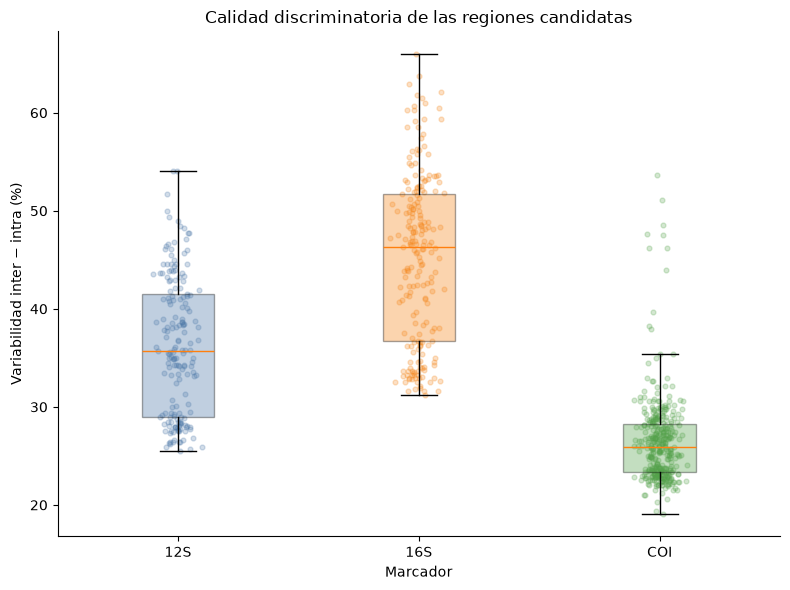

In [112]:
fig, ax = plt.subplots(figsize=(8, 6))

datos_plot = [
    regiones_candidatas.loc[
        regiones_candidatas["gen"] == gen,
        "calidad_region_pct"
    ].values
    for gen in ["12S", "16S", "COI"]
]

bp = ax.boxplot(
    datos_plot,
    tick_labels=["12S", "16S", "COI"],
    patch_artist=True,
    showfliers=False
)

for caja, gen in zip(bp["boxes"], ["12S", "16S", "COI"]):
    caja.set_facecolor(colores[gen])
    caja.set_alpha(0.35)

for i, gen in enumerate(["12S", "16S", "COI"], start=1):

    valores = regiones_candidatas.loc[
        regiones_candidatas["gen"] == gen,
        "calidad_region_pct"
    ].values

    jitter = np.random.normal(
        i,
        0.04,
        size=len(valores)
    )

    ax.scatter(
        jitter,
        valores,
        color=colores[gen],
        alpha=0.25,
        s=12
    )

ax.set_ylabel("Variabilidad inter − intra (%)")
ax.set_xlabel("Marcador")
ax.set_title("Calidad discriminatoria de las regiones candidatas")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()